# Hybrid fraud detection for online accommodation reservations

## 1. Summary

**What this project does.** An online reservation platform checks every payment attempt with fraud rules. The rules catch the attacks, but they also send many good customers to an extra check. This project keeps the rules and adds a machine learning model that gives every attempt a risk score. Where a rule is sure, the rule decides. Where a rule is only a hint, the risk score decides. We call this the hybrid system, and we compare it with the rules alone.

**The data.** Synthetic transaction data from a fraud analytics case study: 79,557 payment attempts from January 2022. It has no confirmed fraud label, so we build our own from the links between attempts (section 7).

![The flow of the hybrid system](../docs/hybrid_flow.png)

The diagram shows the path of one attempt. A hard rule acts on its own. If only soft rules fire, the risk score and the value band of the reservation choose the action. If no rule fires, the attempt is allowed and its score is only logged. The feedback loop at the bottom is a design for a live system and is not built here.

**How to read the comparison.** The rules are the production rule set, designed on all available history. The Isolation Forest is a second signal on top of them. Everything the ML layer learns (the model, the risk bands and the price cut points) comes from days 1 to 14 only, and the comparison runs on days 15 to 31 with the same rules on both sides.

**How to read this notebook.** Sections 2 to 6 show the data: a first look, the quality checks, what is normal and what is odd, and the split by time. Sections 7 to 12 run the steps one by one: label, features, rules, risk model, explanations and decisions. Sections 13 and 14 hold the results, and section 15 the recommendations, limits and next steps. After every table and chart there is a short note with the same parts: what this shows, what we see, what it means if the number goes up or down, and what we do with it.

## 2. Setup

This section loads the tools and the project settings. Every threshold and setting lives in `config.yaml`, so a change needs no code edit. The notebook does not hold any logic of its own: it calls the classes in `src/` one step at a time and shows what each step gives back.

In [1]:
import copy
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Run from the project folder, so that "src" and "config.yaml" are found.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import shap

from src.data_loader import DataLoader, load_config
from src.data_profile import DataProfiler
from src.data_quality import DataQualityChecker
from src.decision import FRICTION_ACTIONS, DecisionPolicy
from src.evaluation import Evaluator
from src.features import MODEL_FEATURES, FeatureBuilder
from src.labels import InvestigationLabeler
from src.pipeline import FraudPipeline
from src.risk_model import RiskModel
from src.rules import RuleEngine
from src.split_check import SplitChecker

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

config = load_config()

pd.DataFrame({
    "setting": [
        "data file",
        "last training day",
        "risk band percentiles",
        "value band percentiles",
        "high price percentile",
        "random seed",
    ],
    "value": [
        config["data"]["path"],
        config["split"]["train_last_day"],
        config["model"]["band_percentiles"],
        config["features"]["value_band_percentiles"],
        config["features"]["high_price_percentile"],
        config["model"]["random_state"],
    ],
})

,setting,value
0,data file,data/transactions.csv
1,last training day,14
2,risk band percentiles,"[95, 99]"
3,value band percentiles,"[33, 66]"
4,high price percentile,90
5,random seed,42


**What this shows:** the main settings from `config.yaml`.

**What we see:** days 1 to 14 are the training days, and days 15 to 31 are the test days. The risk bands are cut at the 95th and 99th percentile of the risk scores. A percentile is the value below which a given share of the data falls: 95% of the scores are below the 95th percentile. The value bands are cut at the 33rd and 66th percentile of the price. Every random step uses the seed 42, so a new run gives the same numbers.

**What we do with it:** every later step reads its settings from this file.

## 3. First look at the data

Before we build anything, we look at the raw data. `DataLoader.load()` reads `data/transactions.csv`, runs the blocking checks (section 4) and adds a `day` column (1 to 31). The data is synthetic transaction data from a fraud analytics case study. Then `DataProfiler.column_profile()` and `DataProfiler.dataset_summary()` describe the columns and the size of the data.

In [2]:
loader = DataLoader(config)
profiler = DataProfiler(config)
checker = DataQualityChecker(config)

df = loader.load()
print(f"{len(df):,} payment attempts, {df.shape[1]} columns (17 from the file and the new 'day' column)")

79,557 payment attempts, 18 columns (17 from the file and the new 'day' column)


In [3]:
profiler.column_profile(df)

,column,meaning,type,distinct values,example,min,max
0,transaction_id,Unique ID of the payment attempt,int64,79557,922278674,,
1,creation_date,Day the reservation was created (no time of day),datetime64[ns],31,2022-01-07,,
2,ip_id,ID of the IP address the booker used,object,77181,e1fcad6672daa92bd6b5020fd954ff5a,,
3,credit_card_id,ID of the card used for the payment,object,77949,0bb5ba2d7dd11cd0cf12f6db8fba25b0,,
4,booker_country,Country the reservation was made from,object,15,Germany,,
5,card_issuing_country,Country where the card was issued,object,15,Germany,,
6,hotel_country,Country of the property,object,15,Germany,,
7,hotel_id,ID of the property listed on the platform,int64,51775,90084,,
8,language,Language of the website the booker used,object,15,German,,
9,price_euro,Total value of the reservation in EUR,float64,71185,3478.16,200.12,4999.2


**What this shows:** one row per column of the file: what it means, its type, how many different values it has, one example value, and the smallest and largest value of the number columns.

**What we see:** the IDs of the IP, the card and the email are hashed text, so we can compare them but not read them. Almost every attempt has its own card (77,949 cards), email (77,954) and IP (77,181). There are 15 countries, 15 site languages, 5 payment methods and 5 payment results. Prices go from 200 to 4,999 EUR, the book window from 0 to 99 days, the stay from 0 to 29 nights, and the property age from 0 to 46 months.

**What we do with it:** the column list tells us which signals we can use. The meanings come from the source of the data, and nobody can confirm them for us. Two of them do not fully fit the data, so we read them in our own way. We read booker_country as the country the booker entered, because one IP comes with up to 15 countries (check Q10 in section 4). We read credit_card_id as the ID of the card or the payment account, because PayPal and Klarna attempts also have one (check Q9). These readings are our interpretation, and the brief lists them next to the source descriptions. There is no customer ID and no time of day, so we cannot follow a customer over time or order the attempts of one day.

In [4]:
df.head()

,transaction_id,creation_date,ip_id,credit_card_id,booker_country,card_issuing_country,hotel_country,hotel_id,language,price_euro,book_window,length_of_stay,email_id,email_domain,auth_result,property_age,payment_method,day
0,922278674,2022-01-07,e1fcad6672daa92bd6b5020fd954ff5a,0bb5ba2d7dd11cd0cf12f6db8fba25b0,Germany,Germany,Germany,90084,German,3478.16,89,5,9dfb54bfcfeebaffb4774a374d1a52dc,@strawberry.com,AUTHORISED,30,mastercard,7
1,819686771,2022-01-22,5a71be20c6d46f2393be71d7199b607e,bb01aa67b20f28b8ce29e3a60d8ab276,Iceland,Iceland,Bulgaria,56417,Icelandic,2476.98,30,13,cc6996a700b82b759c87d0b2ddf64611,@grapefruit.com,AUTHORISED,28,visa,22
2,755157875,2022-01-09,c25608c42c31aeafa1d7ad8012906b3c,09f5288f5bdd02b54c38825d1c29f5c9,Norway,Norway,Norway,22278,Slovak,2855.06,68,17,eda9797a55551a5b8006bbee110b44a7,@grape.com,AUTHORISED,29,mastercard,9
3,601281336,2022-01-17,e782033ba3a8dd86edd4f798579a0f92,288c1c58f5255956d78e2e526f9a2910,Spain,Spain,Italy,44946,Spanish,3780.31,11,17,731b84fa086015230b89780553603ea8,@blueberry.com,AUTHORISED,33,visa,17
4,152684295,2022-01-25,3895fc0fecfd3d4f31d7d708fc592098,95d0d8ec61b03bf7fd4250086313ab22,Germany,Germany,Norway,91658,German,2115.12,64,13,406e2e3950a284067b393d7137212f64,@lemon.com,AUTHORISED,27,paypal,25


**What this shows:** the first 5 rows of the data.

**What we see:** one row is one payment attempt for a reservation. It says who paid (IP, card, email, booker country), for what (property, country, price, dates) and what the payment provider answered (auth_result). The data has no reservation ID and no time of day, so we cannot link a failed payment to a later attempt for the same reservation. We also see no sign of such retries: 12,444 of the 13,686 attempts that were not authorised use a card and an email that appear only once in the month.

In [5]:
profiler.dataset_summary(df)

,item,count,used in more than one attempt,attempts covered by these
0,attempts,79557,<NA>,<NA>
1,days,31,<NA>,<NA>
2,distinct cards,77949,6,1614
3,distinct emails,77954,11,1614
4,distinct IPs,77181,4,2380
5,distinct properties,51775,19342,47124


**What this shows:** the size of the data, and for cards, emails, IPs and properties: how many there are, how many are used in more than one attempt, and how many attempts these reused IDs cover.

**What we see:** 79,557 attempts over 31 days. Only 6 cards, 11 emails and 4 IPs are used more than once in the whole month, and they cover 1,614, 1,614 and 2,380 attempts. Every other card, email and IP is used exactly once. Properties are different: 19,342 properties have more than one reservation, which is normal for a hotel.

**If it goes up:** more cards, emails or IPs that come back. In real traffic that can be loyal customers, so we would need customer history to tell them apart from attackers.

**If it goes down:** fewer repeated IDs, and fewer of the attack traces that our label and rules use.

**What we do with it:** in this month almost no normal customer repeats a card, email or IP. So an ID that comes back hundreds of times is a strong sign of an attack. Section 7 builds the label on this idea.

## 4. Data quality

We check the data in two ways. The blocking checks (`DataLoader.check_structure()`) stop the run if the data is broken, for example if a column is missing. The quality report (`DataQualityChecker.quality_report()`) runs ten more checks. It never stops the run and never changes the data: it tells the reader what is odd, with a status of OK, NOTE (good to know) or WARNING (looks like a data error).

In [6]:
for line in loader.passed_checks:
    print("PASSED:", line)

PASSED: All 17 columns exist.
PASSED: There are no missing values and no empty text values.
PASSED: Every transaction_id is unique.
PASSED: creation_date is a date, price_euro is numeric, and book_window, length_of_stay, property_age are whole numbers.
PASSED: auth_result has only the 5 known values.


**What this shows:** the five blocking checks. `load()` already ran them and kept the result in `passed_checks`, so we only print it here.

**What we see:** all five pass: all 17 columns exist, nothing is missing, every transaction_id is unique, every column has the right type, and auth_result has only the 5 known values.

**What we do with it:** we can trust the structure of the file, so the next steps can use every column without extra cleaning.

In [7]:
quality_report = checker.quality_report(df)
quality_report

,id,check,what we check,result,rows,share of rows (%),status,action
0,Q1,Dates,"All dates are in one month, and every day has attempts","1 January 2022 to 31 January 2022, 31 days, 2,439 to 3,308 attempts per day",0,0.0,OK,None
1,Q2,Time of day,creation_date has a time,"Dates only, no time",79557,100.0,NOTE,None. Same-day counts also include later attempts of that day
2,Q3,Repeated attempts,Rows that are the same in every column except transaction_id,0 repeated rows,0,0.0,OK,None
3,Q4,Value ranges,"price_euro > 0, and book_window, length_of_stay and property_age >= 0","0 rows out of range. Price 200 to 4,999 EUR, book window 0 to 99 days, stay 0 to 29 nights, property age 0 to 46 months",0,0.0,OK,None
4,Q5,Zero-night stays,length_of_stay == 0,338 attempts,338,0.4,WARNING,Keep. Rule R8 uses them
5,Q6,Text values,"Spaces at the start or end, or the same value in a different case",None,0,0.0,OK,None
6,Q7,Known values,"Every language is in the language map, and the three country columns use the same names","15 languages, 15 in the map; 15 countries, 15 used in all three columns",0,0.0,OK,None. R7 can check every attempt
7,Q8,One value per ID,"Each card has one issuing country and payment method, each email one domain, each property one country",No conflicts,0,0.0,OK,None
8,Q9,Card ID for every payment method,credit_card_id and card_issuing_country are also filled for paypal and klarna,"8,373 paypal or klarna attempts with a card ID",8373,10.5,NOTE,Keep. We treat credit_card_id as the ID of the card or account behind every payment
9,Q10,IDs with more than one booker country,"IPs, cards and emails seen with more than one booker_country","4 IPs (2,380 attempts), 5 cards (1,479 attempts), 10 emails (1,479 attempts)",2380,3.0,NOTE,Keep. This is not a data error but a fraud signal


**What this shows:** the ten quality checks Q1 to Q10, with what each one checks, what it found, how many rows it concerns, its status and our action. The status is OK if the check found nothing, NOTE if it found something that is not an error but that the reader needs to know, and WARNING if it found something that looks like a data error. We keep WARNING rows and explain them.

**What we see:** six checks are OK. Q5 is a WARNING: 338 stays of 0 nights (0.4% of the 79,557 attempts). Q2, Q9 and Q10 are NOTEs: there is no time of day, 8,373 PayPal or Klarna attempts (10.5% of the 79,557) also have a card ID, and 4 IPs, 5 cards and 10 emails come with more than one booker country (2,380 of the 79,557 attempts, 3.0%). No row needs a fix.

**If it goes up:** more WARNING rows in next month's data would point to a problem in the data feed. Look at those rows by hand before the rules and the model use them.

**If it goes down:** cleaner data, but a lower Q10 can also mean fewer attacks, not better data.

**What we do with it:** the cells below explain each NOTE and WARNING row.

In [8]:
df["creation_date"].head(3)

0   2022-01-07
1   2022-01-22
2   2022-01-09
Name: creation_date, dtype: datetime64[ns]

**What this shows:** check Q2. The first three values of creation_date.

**What we see:** creation_date holds only a date, never a time. So we cannot put the attempts of one day in order.

**If it goes up:** not a number here. If a later file has a time of day, we can count only the attempts before each attempt, and the same-day counts become exact.

**What we do with it:** every same-day count (for example, attempts per card on the same day) also includes later attempts of that day. This makes the results a little optimistic. We say so wherever we use these counts.

In [9]:
zero_night_stays = df[df["length_of_stay"] == 0]
print(f"{len(zero_night_stays)} attempts with 0 nights ({len(zero_night_stays) / len(df):.1%})")
zero_night_stays["auth_result"].value_counts()

338 attempts with 0 nights (0.4%)


auth_result
REFUSED                                 161
AUTHORISED                              152
FRAUD                                    10
ERROR                                     8
INSUFFICIENT_FUNDS_OR_LIMIT_EXCEEDED      7
Name: count, dtype: int64

**What this shows:** check Q5. The attempts with a length of stay of 0 nights, and their payment results. A real reservation has at least one night.

**What we see:** 338 attempts (0.4% of the 79,557) have 0 nights. 179 of them (53%, 179 of 338) were declined (161 REFUSED, 10 FRAUD, 8 ERROR), while a normal day has a decline share of about 9% (6,458 declines among the 73,154 attempts of all days except days 10 and 11). We keep them. They are not a loading error, and rule R8 uses them as a warning sign.

**If it goes up:** more reservations without a night. This can be a bug in the reservation form or the data feed, or fraudsters who make fake reservations to test cards.

**If it goes down:** fewer broken reservations, and R8 fires less often.

In [10]:
df["payment_method"].value_counts().to_frame("attempts")

,attempts
payment_method,
visa,31061
mastercard,27026
american express,13097
paypal,6905
klarna,1468


**What this shows:** check Q9. The attempts per payment method. The file has no missing values, so every attempt has a credit_card_id and a card_issuing_country.

**What we see:** PayPal (6,905 attempts) and Klarna (1,468 attempts) are not cards, but all 8,373 of these attempts still have a card ID and a card country.

**If it goes up:** a larger share of wallet payments. The card ID then stands more often for an account and not for a plastic card.

**If it goes down:** more payments by card, and the card ID means a real card more often.

**What we do with it:** we keep these rows. We treat credit_card_id as the ID of the card or account behind every payment, so the card rules work for all payment methods.

In [11]:
checker.ids_from_many_countries(df)

,id type,id,booker_countries,attempts
0,ip_id,7e4f0027cda022e8d2e0ddbfbbdd5206,15,901
1,ip_id,7065ee7d9882c44278879f4b4b154d03,15,601
2,ip_id,933c900af847f49475eb6a9bcf70d735,13,459
3,ip_id,06a9ec59540dbae94271add0496cde52,13,419
4,credit_card_id,5e3a0db720f17bdf1a4ec149cdeab0e6,14,412
5,credit_card_id,d493eb00e15c3cf9e633790abadd36a4,14,341
6,credit_card_id,7b9360795e691db76879519c67dcac90,14,300
7,credit_card_id,9e02d37357a99d0bc0ee070ddde4db0a,11,225
8,credit_card_id,93e15c64ed76791b041f4a077ea248d2,9,201
9,email_id,e0293420f019cf955f2e66e90c314f99,12,230


**What this shows:** check Q10. The IPs, cards and emails that come with more than one booker country, with the number of countries and attempts for each.

**What we see:** 4 IPs (2,380 attempts), 5 cards (1,479 attempts) and 10 emails (1,479 attempts). Each of these IDs was used 75 to 901 times. The profile in section 3 counts 6 reused cards and 11 reused emails, one more of each. The missing card and email belong to the second attack: they were used together 135 times over 30 days, always with the same booker country, so Q10 does not list them. A normal guest has one booker country, so this is not a data error. It is a trace of the attacks.

**If it goes up:** more IDs with many countries. This points to new attacks, or to shared networks such as a company VPN.

**If it goes down:** fewer traces of these attacks. Fraudsters may also change their IP and email more often, which makes them harder to link.

**What we do with it:** we keep these rows. Section 7 links the attempts that share an ID and uses these links as our fraud label.

**What we changed in the data: nothing.** All blocking checks pass, and no quality check found a row that needs a fix. The odd rows (0-night stays, IDs from many countries) are exactly the rows that can carry fraud signals. Removing them would hide the attacks we want to find.

## 5. Explore the data

Before any rule or model, we look at what is normal in this data and what is odd. `DataProfiler.auth_result_mix()` and `DataProfiler.daily_overview()` give the payment results and the attempts per day. Then we draw the main number columns and count the attempts per country, payment method and language.

In [12]:
profiler.auth_result_mix(df)

,auth_result,attempts,share (%)
0,AUTHORISED,65871,82.8
1,INSUFFICIENT_FUNDS_OR_LIMIT_EXCEEDED,5540,7.0
2,ERROR,3821,4.8
3,REFUSED,3495,4.4
4,FRAUD,830,1.0


**What this shows:** how the payment provider answered the attempts: the count and the share of each auth_result.

**What we see:** 82.8% of the attempts (65,871 of 79,557) are AUTHORISED (approved). 7.0% (5,540) fail for lack of money, 4.8% (3,821) for a technical ERROR and 4.4% (3,495) are REFUSED without a reason. Only 1.0% (830 attempts) are declined as FRAUD.

**If it goes up:** a higher FRAUD or REFUSED share can mean more stolen cards being tested. A higher ERROR share points to a technical problem at the payment provider.

**If it goes down:** fewer declines. That is good for customers, but it can also mean that fraud gets through.

**What we do with it:** FRAUD is only the payment provider's suspicion, not confirmed fraud. Section 7 shows why we do not use it as our label. "Declined" in this project means REFUSED, FRAUD or ERROR.

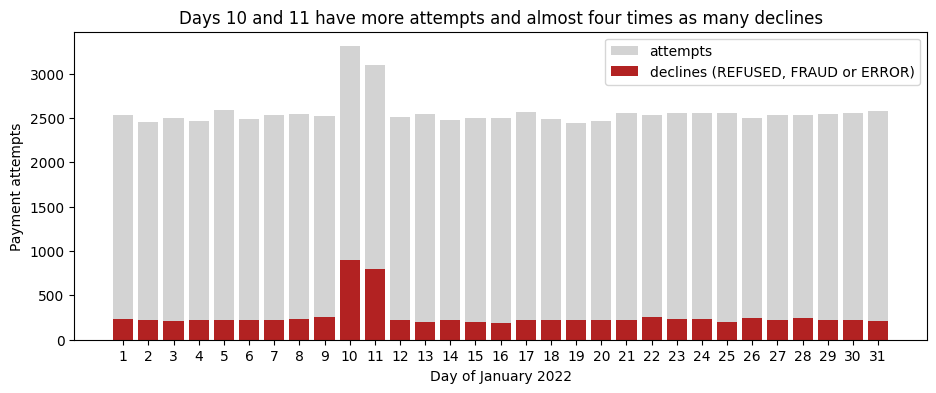

,day,attempts,declines,decline share (%)
9,10,3308,896,27.1
10,11,3095,792,25.6
4,5,2593,226,8.7
30,31,2582,212,8.2


In [13]:
daily = profiler.daily_overview(df)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(daily["day"], daily["attempts"], color="lightgray", label="attempts")
ax.bar(daily["day"], daily["declines"], color="firebrick", label="declines (REFUSED, FRAUD or ERROR)")
ax.set_title("Days 10 and 11 have more attempts and almost four times as many declines")
ax.set_xlabel("Day of January 2022")
ax.set_ylabel("Payment attempts")
ax.set_xticks(daily["day"])
ax.legend()
plt.show()

daily.sort_values("attempts", ascending=False).head(4)

**What this shows:** the attempts (gray) and the declined attempts (red) per day. The table lists the four busiest days.

**What we see:** most days have 2,439 to 2,593 attempts and a decline share of 7.5% (day 16: 188 declines of 2,503 attempts) to 10.1% (day 9: 255 of 2,528). Days 10 and 11 stand out: 3,308 and 3,095 attempts, with 896 and 792 declines (27.1% = 896 of 3,308 and 25.6% = 792 of 3,095). Someone made many extra attempts on these two days, and most of them failed. This looks like an attack.

**If it goes up:** a day with many more attempts and declines than usual is an early alarm for an attack, such as card testing (trying many stolen cards to see which ones work).

**If it goes down:** fewer attempts on a day can mean a quiet day, or a broken data feed. Check the feed first.

**What we do with it:** days 10 and 11 are in the training days. Section 7 shows which attack causes them.

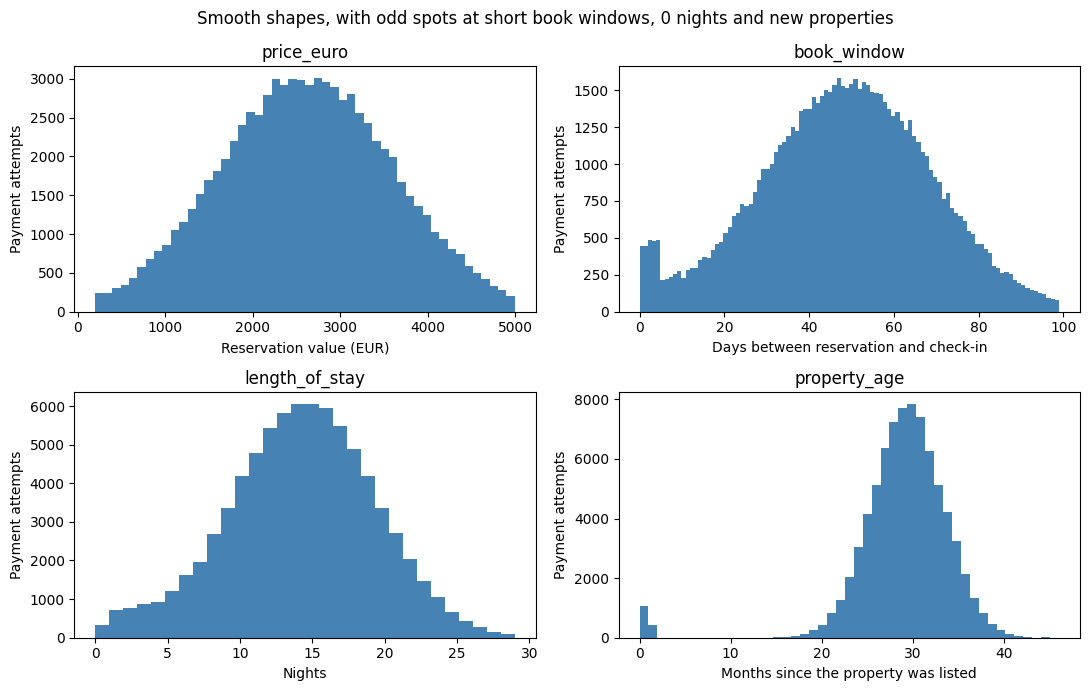

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
histograms = [
    ("price_euro", "Reservation value (EUR)", 50),
    ("book_window", "Days between reservation and check-in", 100),
    ("length_of_stay", "Nights", 30),
    ("property_age", "Months since the property was listed", 47),
]
for ax, (column, label, bins) in zip(axes.flat, histograms):
    ax.hist(df[column], bins=bins, color="steelblue")
    ax.set_xlabel(label)
    ax.set_ylabel("Payment attempts")
    ax.set_title(column)
fig.suptitle("Smooth shapes, with odd spots at short book windows, 0 nights and new properties")
fig.tight_layout()
plt.show()

**What this shows:** histograms of the four number columns. A histogram puts the values into bins and counts the attempts in each bin.

**What we see:**
- **price_euro:** a smooth hill from 200 to 4,999 EUR, with the middle at about 2,600 EUR. Nothing odd.
- **book_window:** a hill with its middle at about 50 days, and a small peak at 0 to 4 days: 443 to 488 attempts for each of these values, against 214 to 281 for each value from 5 to 11 days. Last-minute reservations are more common than the smooth shape would expect.
- **length_of_stay:** a hill around 14 nights, with 338 stays of 0 nights (check Q5).
- **property_age:** most properties are 13 to 46 months old. A separate group of 1,479 attempts is at properties of 0 or 1 month. No property is 2 to 12 months old.

**If it goes up:** a larger peak at short book windows or at new properties would point to more fake properties or fast money-out schemes.

**If it goes down:** fewer odd spots, so the data looks more like normal travel.

**What we do with it:** these odd spots are the starting point for rule R4 (new property and short book window), R8 (0 nights) and R12 (last minute and high price).

In [15]:
young_properties = df[df["property_age"] < 2]
print(f"{len(young_properties):,} attempts at {young_properties['hotel_id'].nunique()} properties younger than 2 months")
profiler.decline_share_by(young_properties, "day")

1,479 attempts at 7 properties younger than 2 months


,day,attempts,declines,decline share (%)
0,10,777,651,83.8
1,11,702,591,84.2


**What this shows:** the attempts at properties younger than 2 months: how many there are and at how many properties, then per day the attempts, the declines and the decline share.

**What we see:** all 1,479 of these attempts are on days 10 and 11, at only 7 properties. 651 of the 777 attempts on day 10 (83.8%) and 591 of the 702 on day 11 (84.2%) were declined, against about 9% on a normal day (6,458 declines among the 73,154 attempts of all days except days 10 and 11). New properties with hundreds of reservations in two days are a classic sign of fake listings that try to collect money fast.

**If it goes up:** more attempts at brand-new properties. The platform should check new listings before their first payout.

**If it goes down:** fewer attempts at new properties, which is the normal case.

**What we do with it:** in this synthetic data every young property belongs to the attack, but in real data many new properties are honest. So we do not build a rule on "new property" alone. Rule R4 adds a short book window.

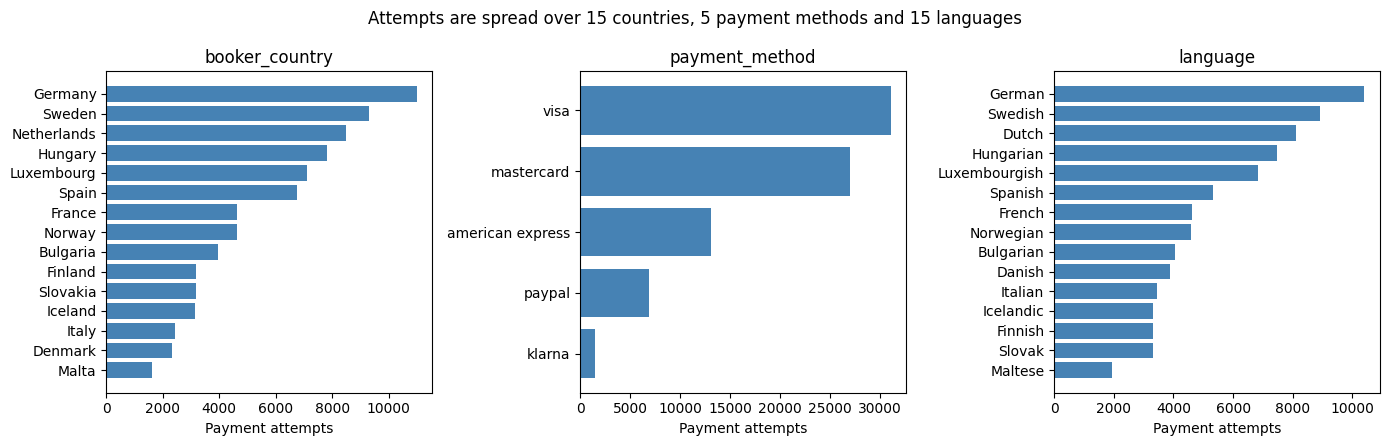

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, column in zip(axes, ["booker_country", "payment_method", "language"]):
    counts = df[column].value_counts().sort_values()
    ax.barh(counts.index, counts.values, color="steelblue")
    ax.set_title(column)
    ax.set_xlabel("Payment attempts")
fig.suptitle("Attempts are spread over 15 countries, 5 payment methods and 15 languages")
fig.tight_layout()
plt.show()

**What this shows:** the number of attempts per booker country, per payment method and per site language.

**What we see:** Germany is the largest booker country (10,995 attempts) and Malta the smallest (1,625). Visa (39.0%, 31,061 of the 79,557 attempts) and Mastercard (34.0%, 27,026) are the main payment methods, then American Express (16.5%, 13,097), PayPal (8.7%, 6,905) and Klarna (1.8%, 1,468). The languages follow the countries: German is the most used (10,403 attempts) and Maltese the least (1,945). No country, method or language takes an odd share.

**If it goes up:** a sudden jump of one country or payment method can be a marketing campaign, or attackers who use cards from one country.

**If it goes down:** a drop can mean a payment method has a problem, or a market got smaller.

**What we do with it:** we do not build rules on a single country or email domain. Such values only fit this month, and fraudsters change them the next month.

In [17]:
attack_days = [10, 11]
other_days = df[~df["day"].isin(attack_days)]

for column in ["payment_method", "booker_country", "email_domain"]:
    all_days = profiler.decline_share_by(df, column)
    without_attack_days = profiler.decline_share_by(other_days, column).set_index(column)["decline share (%)"]
    all_days["decline share without days 10 and 11 (%)"] = all_days[column].map(without_attack_days)
    print(f"Decline share per {column}, highest first")
    display(all_days.sort_values("decline share (%)", ascending=False).head(5))

Decline share per payment_method, highest first


,payment_method,attempts,declines,decline share (%),decline share without days 10 and 11 (%)
0,american express,13097,2236,17.1,8.6
1,klarna,1468,152,10.4,10.1
2,mastercard,27026,2406,8.9,8.8
4,visa,31061,2753,8.9,8.9
3,paypal,6905,599,8.7,8.6


Decline share per booker_country, highest first


,booker_country,attempts,declines,decline share (%),decline share without days 10 and 11 (%)
13,Spain,6767,1646,24.3,9.3
3,France,4618,442,9.6,9.4
2,Finland,3167,297,9.4,9.1
0,Bulgaria,3952,372,9.4,9.3
12,Slovakia,3160,292,9.2,9.0


Decline share per email_domain, highest first


,email_domain,attempts,declines,decline share (%),decline share without days 10 and 11 (%)
13,@papaya.com,6959,1704,24.5,8.3
16,@plum.com,2363,228,9.6,9.5
15,@pineapple.com,2995,281,9.4,9.5
0,@apricot.com,9456,875,9.3,9.2
10,@mango.com,1544,143,9.3,9.2


**What this shows:** the decline share (REFUSED, FRAUD or ERROR) per payment method, per booker country and per email domain, made with `DataProfiler.decline_share_by()`. Each table shows the 5 values with the highest share, once for all days and once without days 10 and 11.

**What we see:** most values have a decline share of about 8% to 10%. Three values stand out: American Express (17.1%, 2,236 declines of 13,097 attempts), Spain (24.3%, 1,646 of 6,767) and the email domain @papaya.com (24.5%, 1,704 of 6,959). Without days 10 and 11, the three fall back to the normal level: American Express to 8.6% (934 of 10,851), Spain to 9.3% (471 of 5,070) and @papaya.com to 8.3% (427 of 5,132). The highest share is then 10.1% for payment methods (Klarna, the smallest method: 138 of 1,361), 9.4% for countries (France: 404 of 4,315) and 9.5% for email domains (@plum.com: 210 of 2,201). So no payment method, country or domain has a problem of its own. The high shares come from the two attack days.

**If it goes up:** a payment method with a higher decline share on all days points to a technical problem at that provider. A country or domain with a higher share on a few days points to an attack that uses it.

**If it goes down:** fewer declines for that value, which is normal, or a provider that lets more payments through without checks.

**What we do with it:** the next cell checks which attempts cause the high shares.

In [18]:
for column in ["payment_method", "booker_country", "email_domain"]:
    display(profiler.decline_share_by(young_properties, column).drop(columns="decline share (%)").sort_values("attempts", ascending=False).head(3))

,payment_method,attempts,declines
0,american express,1479,1242


,booker_country,attempts,declines
13,Spain,1366,1144
11,Norway,12,9
12,Slovakia,12,11


,email_domain,attempts,declines
0,@papaya.com,1479,1242


**What this shows:** the three most common payment methods, booker countries and email domains of the 1,479 attempts at properties younger than 2 months (the attack on days 10 and 11), each with its attempts and declines.

**What we see:** all 1,479 attempts use American Express and an @papaya.com email, and 1,242 of them were declined. 1,366 of them come from Spain, with 1,144 declines. The next countries have only 12 attempts each (Norway: 9 declines, Slovakia: 11). 

**If it goes up:** a larger attack on one payment method or one domain makes its decline share jump, even if the method or domain itself is fine.

**If it goes down:** the decline shares per method, country and domain stay close together.

**What we do with it:** it would be easy to write a rule such as "American Express from Spain with @papaya.com". We do not, because such a rule only fits this month: fraudsters change their card type, country and email domain the next month, while good customers from Spain would keep getting blocked. Our rules look at behaviour instead (repeated cards, new properties, many attempts per day), and confirmed values go on the hotlist (rule R13) after an investigation.

## 6. Train and test split

We split the data by time with `DataLoader.split()`, and `DataProfiler.split_summary()` shows the size of the two parts. Days 1 to 14 are the training days: we use them to learn the model, the cut points and the price limits. Days 15 to 31 are the test days: we only use them to check the results. We learn from the past and test on the future, as in real life.

In [19]:
train_df, test_df = loader.split(df)

profiler.split_summary(train_df, test_df)

,split,attempts,days
0,train (days 1 to 14),36590,14
1,test (days 15 to 31),42967,17


**What this shows:** the attempts and the days in each part of the split.

**What we see:** the training part has 36,590 attempts over 14 days, and the test part has 42,967 attempts over 17 days.

**What we do with it:** a random split would put attempts from the same attack in both parts, and the results would look better than they are. With a time split, an attack that starts on day 15 or later is new to the model, just as it would be in a live system. Note: the features in section 8 are built on all days at once and split afterwards. This is not leakage: each feature only looks at the same day or earlier days, so a test day sees only its own past, as it would in a live system. Building them separately would leave the first test days without their history from the last training days.

### Do the two parts look alike?

A time split only gives a fair test if the training days and the test days hold the same kind of traffic. `SplitChecker.psi_table()` checks this with the Population Stability Index (PSI). The PSI is one number per column that says how much the mix of values changed between two tables. 0 means no change. As a rule of thumb, below 0.1 a column is stable, from 0.1 to 0.25 it has a small shift, and from 0.25 on it has a large shift. The limits are in `config.yaml`. A number column is first cut into 10 value ranges that each hold about the same number of training attempts.

In [20]:
split_checker = SplitChecker(config)
raw_columns = config["split_check"]["raw_columns"]

split_checker.psi_table(train_df, test_df, raw_columns)

,column,kind,groups,psi,status
0,language,category,15,0.041,stable
1,card_issuing_country,category,15,0.038,stable
2,hotel_country,category,15,0.027,stable
3,auth_result,category,5,0.025,stable
4,email_domain,category,19,0.018,stable
5,property_age,number,10,0.017,stable
6,booker_country,category,15,0.015,stable
7,payment_method,category,5,0.012,stable
8,book_window,number,10,0.006,stable
9,length_of_stay,number,10,0.006,stable


**What this shows:** the PSI of 11 raw columns, training days against test days. The ID columns are left out, because almost every ID is used only once.

**What we see:** all 11 columns are stable. The largest PSI is 0.041 (language), far below the limit of 0.1. price_euro has the smallest PSI, 0.001. This matters, because the value bands and the price limit of rule R12 are learned from the prices of the training days.

**If it goes up:** the test days hold other traffic than the training days. From 0.25 on, the limits and the model that we learned on the training days may not fit the test days, and we would look at that column before we trust the test results.

**If it goes down:** the two parts look more alike.

**What we do with it:** we keep day 14 as the last training day. The PSI says that a column changed, not why, so the next table looks at the values behind the two largest changes that we can explain with section 5.

In [21]:
for column in ["language", "auth_result"]:
    print(f"Groups of {column} with the largest change")
    display(split_checker.group_shares(train_df, test_df, column).head(4))

Groups of language with the largest change


,group,train share (%),test share (%),psi part
0,Danish,6.92,3.13,0.0301
1,Italian,3.26,5.25,0.0095
2,Swedish,10.89,11.46,0.0003
3,Bulgarian,5.24,4.94,0.0002


Groups of auth_result with the largest change


,group,train share (%),test share (%),psi part
0,REFUSED,6.11,2.93,0.0234
1,AUTHORISED,81.37,84.01,0.0008
2,INSUFFICIENT_FUNDS_OR_LIMIT_EXCEEDED,6.69,7.19,0.0004
3,FRAUD,1.07,1.02,0.0000


**What this shows:** `SplitChecker.group_shares()` for language and auth_result: the share of each value in the training days and in the test days, and its part of the PSI. The PSI of a column is the sum of these parts.

**What we see:** a few values carry almost the whole change. Danish falls from 6.92% of the training attempts (2,531 of 36,590) to 3.13% of the test attempts (1,344 of 42,967), and Italian rises from 3.26% (1,192) to 5.25% (2,256). REFUSED falls from 6.11% (2,236) to 2.93% (1,259). The FRAUD share stays the same: 1.07% (391) and 1.02% (439).

**If it goes up:** a value with a larger psi part explains more of the change in its column.

**If it goes down:** the value has about the same share in both parts.

**What we do with it:** section 5 showed that days 10 and 11 hold many extra attempts with many declines. The next table checks if these two days explain the change.

In [22]:
calm_train_df = train_df[~train_df["day"].isin(attack_days)]

split_checker.psi_table(calm_train_df, test_df, raw_columns)

,column,kind,groups,psi,status
0,card_issuing_country,category,15,0.012,stable
1,language,category,15,0.009,stable
2,hotel_country,category,15,0.007,stable
3,payment_method,category,5,0.004,stable
4,book_window,number,10,0.002,stable
5,price_euro,number,10,0.002,stable
6,length_of_stay,number,10,0.002,stable
7,email_domain,category,19,0.001,stable
8,booker_country,category,15,0.001,stable
9,property_age,number,10,0.000,stable


**What this shows:** the same PSI table, but the training part has no attempts from days 10 and 11.

**What we see:** every PSI is now 0.012 or lower. Language drops from 0.041 to 0.009, auth_result from 0.025 to 0.000 and property_age from 0.017 to 0.000. So most of the small differences in the first table come from the two attack days, not from a change in the normal traffic.

**If it goes up:** the normal traffic itself changed between the two parts, and a time split at this day would be a weaker test.

**If it goes down:** the normal traffic of the two parts looks even more alike.

**What we do with it:** this table is only a check. We keep days 10 and 11 in the training days, because a live system also learns from the days as they were. We run the same PSI check on the model features in section 8. Two more checks of the split come later: intervals around the test metrics in section 10, and other split days in section 13.

## 7. Investigation label

The data has no confirmed fraud label, so we build our own. `InvestigationLabeler.label()` links the attempts that share a card, an email or an IP. A group of linked attempts is called a cluster. An attempt in a cluster of two or more attempts gets label 1 (fraud), and every other attempt gets label 0. Section 3 showed why this works here: normal customers almost never reuse a card, email or IP in this month. The label is our "truth" for the evaluation. The model never learns from it: the label holds only two attacks, so a model trained on it would learn these two attacks by heart and say little about the next one.

In [23]:
labeler = InvestigationLabeler(config)
evaluator = Evaluator(config)

labeled = labeler.label(df)
labeler.describe_clusters(labeled)

,cluster_id,attempts,first day,last day,distinct cards,distinct emails,distinct IPs,distinct properties,AUTHORISED,INSUFFICIENT_FUNDS_OR_LIMIT_EXCEEDED,ERROR,REFUSED,FRAUD,authorised value (EUR)
0,1,1479,10,11,5,10,3,7,237,0,0,1201,41,700012.0
1,2,901,1,31,767,767,1,590,777,50,48,12,14,2718897.0


**What this shows:** the clusters of the whole month, one row per cluster: its attempts, its first and last day, how many different cards, emails, IPs and properties it uses, what the payment provider answered, and the value of its authorised attempts.

**What we see:** there are 2 clusters with 2,380 attempts in total, 3.0% of all 79,557 attempts.
- **Cluster 1** has 1,479 attempts on days 10 and 11 only. It uses just 5 cards, 10 emails and 3 IPs at 7 properties. 1,201 of its attempts were REFUSED, but 237 were authorised, worth 700,012 EUR. This is the attack that section 5 found: a few cards, tried again and again at new properties.
- **Cluster 2** has 901 attempts from day 1 to day 31, all from one single IP, with 767 cards, 767 emails and 590 properties. 777 of its attempts were authorised, worth 2,718,897 EUR. It is quiet: a few dozen attempts per day at most, and the payment provider approves 86% of them (777 of 901), about as many as for normal customers.

**If it goes up:** more or larger clusters mean more attacks, or more normal customers who share an ID (a family card, an office IP). In real data we would have to check new clusters by hand before we call them fraud.

**If it goes down:** fewer attacks, or attackers who use a new card, email and IP for every attempt. This label cannot see such attempts.

**What we do with it:** label 1 means "this attempt belongs to an attack". The evaluation in section 13 uses this label of the whole month.

In [24]:
cluster_names = labeled["cluster_id"].map({1: "cluster 1", 2: "cluster 2"}).astype(object).fillna("not in a cluster")
labeled.groupby(cluster_names).agg(
    attempts=("transaction_id", "count"),
    median_price=("price_euro", "median"),
    median_book_window=("book_window", "median"),
    median_stay=("length_of_stay", "median"),
    booker_countries=("booker_country", "nunique"),
    card_countries=("card_issuing_country", "nunique"),
    property_countries=("hotel_country", "nunique"),
    payment_methods=("payment_method", "nunique"),
).round(0).T

cluster_id,cluster 1,cluster 2,not in a cluster
attempts,1479.0,901.0,77177.0
median_price,2950.0,3823.0,2595.0
median_book_window,2.0,5.0,50.0
median_stay,3.0,2.0,15.0
booker_countries,15.0,15.0,15.0
card_countries,1.0,2.0,15.0
property_countries,1.0,2.0,15.0
payment_methods,1.0,2.0,5.0


**What this shows:** a check of the label. One shared IP could also be an office or a travel agency, so we compare the reservations of each cluster with the attempts outside the clusters: the median price, book window (days before check-in) and stay, and how many different countries and payment methods appear.

**What we see:** the clusters do not look like normal travel. A normal reservation is made 50 days ahead for 15 nights and costs 2,595 EUR. Cluster 1 books 2 days ahead for 3 nights, and cluster 2 books 5 days ahead for 2 nights at 3,823 EUR. Normal traffic uses cards from 15 countries, properties in 15 countries and 5 payment methods. Cluster 1 uses one card country, one property country and one payment method. Cluster 2 uses two of each. But both clusters claim all 15 booker countries, from 3 IPs and from 1 IP.

**If it goes up:** a cluster that looks more like normal traffic (longer stays, many card countries) is more likely a shared office IP or a family card, and its label would be wrong.

**If it goes down:** an even narrower pattern, so an even clearer attack.

**What we do with it:** this is why we trust the label in this data. Hundreds of payment accounts from the same country, each used once for a costly last-minute stay, from one IP that claims 15 home countries, is not what a travel agency looks like. In real data an analyst must do such a check for every new cluster.

In [25]:
train_labeled = labeler.label(train_df)
labeler.describe_clusters(train_labeled)

,cluster_id,attempts,first day,last day,distinct cards,distinct emails,distinct IPs,distinct properties,AUTHORISED,INSUFFICIENT_FUNDS_OR_LIMIT_EXCEEDED,ERROR,REFUSED,FRAUD,authorised value (EUR)
0,1,1479,10,11,5,10,3,7,237,0,0,1201,41,700012.0
1,2,70,1,14,1,1,1,1,70,0,0,0,0,87649.0


**What this shows:** the same table, but the clusters are built from days 1 to 14 alone. This is what an analyst could know at the end of day 14.

**What we see:** cluster 1 is complete, with all 1,479 attempts. Cluster 2 has only 70 attempts so far, and they look very different from the whole month: one card, one email and one IP at one property, and all 70 were authorised (87,649 EUR). So on the training days the second attack is one card that comes back a few times per day.

**If it goes up:** more of the attacks are already visible on the training days, so the hotlist of rule R13 knows more cards, emails, IPs and properties.

**If it goes down:** the attacks start later, and the training days tell us less about them.

**What we do with it:** we use this label for two things that must not look into the future: the precision of the rules on the training days, and the hotlist of rule R13 (section 9).

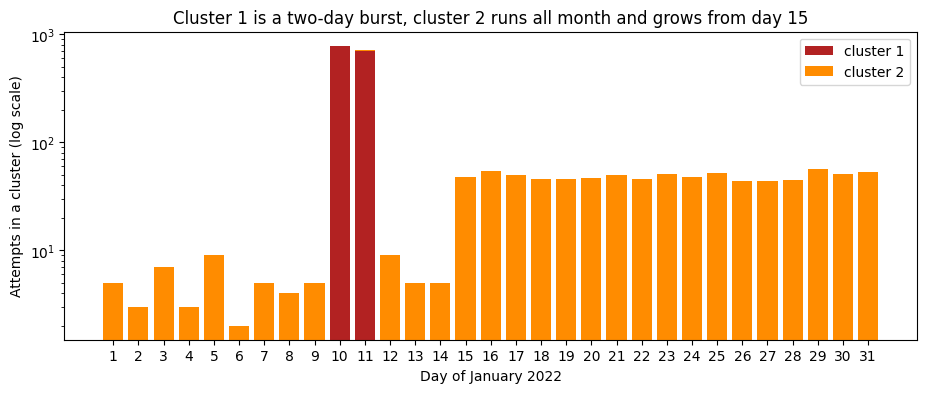

day,9,10,11,12,13,14,15,16
cluster 1,0,777,702,0,0,0,0,0
cluster 2,5,4,4,9,5,5,48,54


In [26]:
daily_clusters = evaluator.daily_cluster_attempts(labeled)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(daily_clusters["day"], daily_clusters["cluster 1"], color="firebrick", label="cluster 1")
ax.bar(daily_clusters["day"], daily_clusters["cluster 2"], bottom=daily_clusters["cluster 1"],
       color="darkorange", label="cluster 2")
ax.set_yscale("log")
ax.set_title("Cluster 1 is a two-day burst, cluster 2 runs all month and grows from day 15")
ax.set_xlabel("Day of January 2022")
ax.set_ylabel("Attempts in a cluster (log scale)")
ax.set_xticks(daily_clusters["day"])
ax.legend()
plt.show()

daily_clusters.set_index("day").loc[9:16].T

**What this shows:** the attempts of each cluster per day (`Evaluator.daily_cluster_attempts()`). The scale is logarithmic, so that the small days stay visible next to the large ones. The table shows days 9 to 16.

**What we see:** cluster 1 has 777 attempts on day 10 and 702 on day 11, and nothing on any other day. Cluster 2 has 2 to 9 attempts per day on days 1 to 14. From day 15 on it has 44 to 56 attempts per day: the quiet attack becomes about ten times larger, right after the training days end.

**If it goes up:** an attack that grows. A burst like cluster 1 is loud and easy to see. A slow rise like cluster 2 is harder to notice from daily counts alone.

**If it goes down:** the attack stops, or it moves to IDs that we cannot link.

**What we do with it:** this is the test that the project needs. The larger part of cluster 2 happens on the test days, so we can check if the rules and the model, built on days 1 to 14, still find it.

**Known limit of this label.** The label means "shares a card, email or IP with another attempt". Any rule or feature that counts repeated cards, emails or IPs therefore agrees with the label by design. This raises the precision of those rules and the ROC AUC of the model. Only the property rules R4, R9 and R10 are independent tests, because the label does not look at the property. We repeat this where it matters.

### Why is the FRAUD answer of the payment provider not our label?

The column auth_result has the value FRAUD for 830 attempts. That looks like a ready label. The next three checks show why we do not use it. They are methods of the Evaluator: `fraud_answer_rate_by()`, `auth_results_by_label()` and `label_check_auc()`.

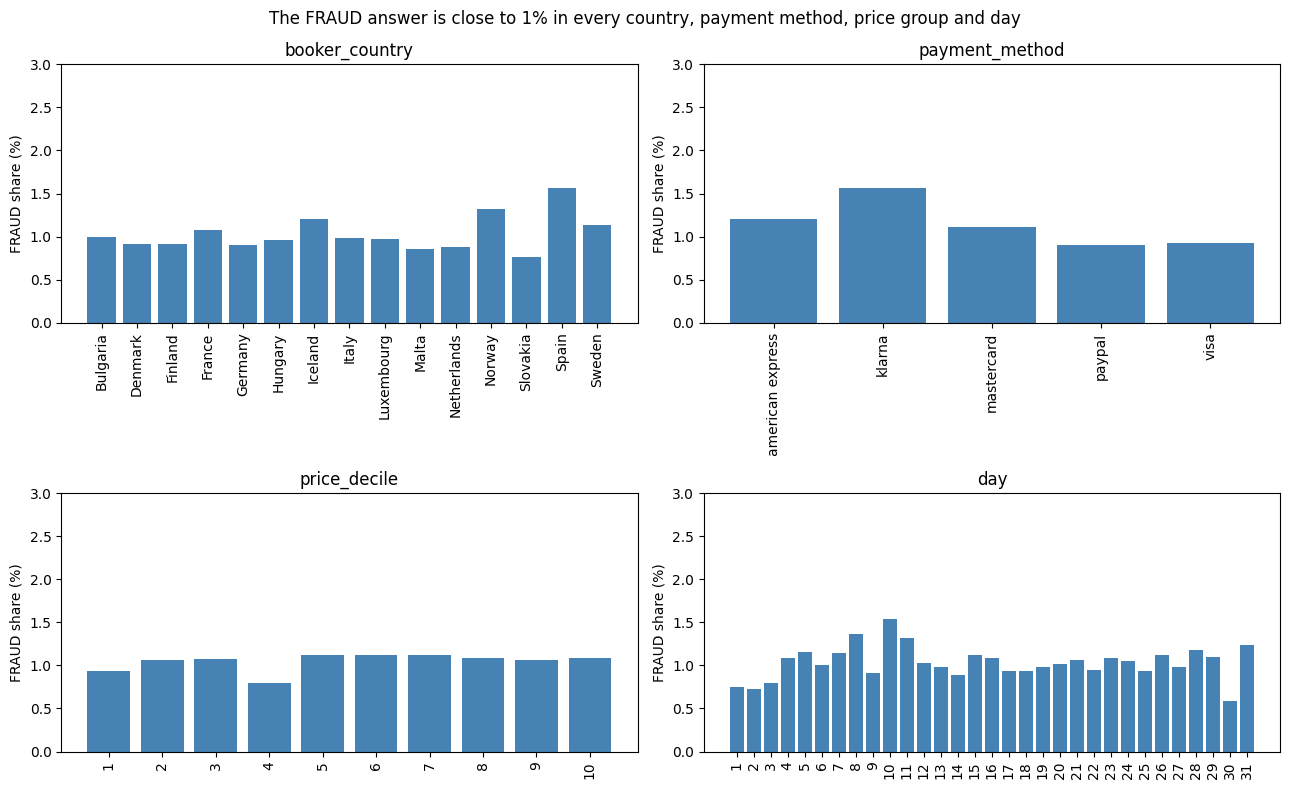

,column,lowest FRAUD share (%),highest FRAUD share (%)
0,booker_country,0.76,1.57
1,payment_method,0.90,1.57
2,price_decile,0.79,1.12
3,day,0.59,1.54


In [27]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ranges = []
for ax, column in zip(axes.flat, ["booker_country", "payment_method", "price_decile", "day"]):
    rates = evaluator.fraud_answer_rate_by(labeled, column)
    ax.bar(rates[column].astype(str), rates["FRAUD share (%)"], color="steelblue")
    ax.set_ylim(0, 3)
    ax.set_title(column)
    ax.set_ylabel("FRAUD share (%)")
    ax.tick_params(axis="x", rotation=90)
    ranges.append({"column": column, "lowest FRAUD share (%)": rates["FRAUD share (%)"].min(),
                   "highest FRAUD share (%)": rates["FRAUD share (%)"].max()})
fig.suptitle("The FRAUD answer is close to 1% in every country, payment method, price group and day")
fig.tight_layout()
plt.show()

pd.DataFrame(ranges)

**What this shows:** the share of attempts that the payment provider declined as FRAUD, per booker country, per payment method, per price group (ten groups of equal size, from cheap to expensive) and per day. The table gives the lowest and the highest share of each chart.

**What we see:** the share is close to 1% everywhere: 0.76% (Slovakia: 24 FRAUD answers of 3,160 attempts) to 1.57% (Spain: 106 of 6,767) per country, 0.90% (PayPal: 62 of 6,905) to 1.57% (Klarna: 23 of 1,468) per payment method, 0.79% (63 of 7,956) to 1.12% (89 of 7,955) per price group and 0.59% (day 30: 15 of 2,560) to 1.54% (day 10: 51 of 3,308) per day. Even days 10 and 11, with their large attack, do not stand out. A signal that follows real fraud would be much higher in some groups than in others.

**If it goes up:** a group with a clearly higher FRAUD share would mean that the answer follows a pattern there, and it would be worth a closer look.

**If it goes down:** an even flatter picture, so even less to learn from.

**What we do with it:** the FRAUD answer looks like it is spread at random. The next table checks it against the clusters.

In [28]:
evaluator.auth_results_by_label(labeled)

label,auth_result,in a cluster,not in a cluster
0,AUTHORISED,1014,64857
1,ERROR,48,3773
2,FRAUD,55,775
3,INSUFFICIENT_FUNDS_OR_LIMIT_EXCEEDED,50,5490
4,REFUSED,1213,2282


**What this shows:** each answer of the payment provider, counted inside and outside the clusters.

**What we see:** only 55 of the 830 FRAUD answers are inside the clusters, and 775 are outside. Inside the clusters, 1,014 of the 2,380 attempts were AUTHORISED and only 55 got the answer FRAUD. So the provider let 43% of the attack attempts through (1,014 of 2,380), and almost all of its FRAUD answers fall on attempts with no link to any attack.

**If it goes up:** more FRAUD answers inside the clusters would mean that the provider sees the same attacks as we do, and its answer would become a useful signal.

**If it goes down:** the provider and our label agree even less.

**What we do with it:** we keep auth_result as a signal of its own. The features count declines (REFUSED, FRAUD or ERROR), which were very high on the attack days, but FRAUD alone is not our label.

In [29]:
label_check_auc = evaluator.label_check_auc(labeled)
print(f"ROC AUC of a model that tries to predict the FRAUD answer: {label_check_auc:.2f}")

ROC AUC of a model that tries to predict the FRAUD answer: 0.52


**What this shows:** a last check. We train a supervised model (gradient boosting, a standard model that learns from labeled examples) to predict the FRAUD answer from the raw columns. ROC AUC is the chance that the model gives a random FRAUD attempt a higher score than a random other attempt: 0.5 is a coin flip, 1.0 is perfect. Each attempt is scored by a model that did not see it (5-fold cross-validation). This model is only a check. It is not part of the system.

**What we see:** the ROC AUC is 0.52 (on all 79,557 attempts, 830 of them with the FRAUD answer), close to a coin flip. The model finds no pattern behind the FRAUD answer.

**If it goes up:** from about 0.7 on, the FRAUD answer would hold a pattern that a supervised model could learn.

**If it goes down:** it cannot go much lower: 0.5 is the level of pure chance.

**What we do with it:** a supervised model on this label would learn noise. So the project uses rules, plus a model that needs no labels (section 10), and it measures both against the investigation label.

## 8. Features

A feature is a number that describes one attempt, for example "how often was this card used today". `FeatureBuilder` builds them in two steps. `fit()` learns three price limits from the training days. `transform()` then adds all feature columns. We call `transform()` once on all days and split afterwards, so that the first test days keep their history from the last training days.

A feature may only use the day of the attempt and the days before it:
- **same day:** the day of the attempt,
- **last 7 days:** the day of the attempt and the 6 days before it,
- **7 days before:** the 7 days before the attempt, without its own day,
- **previous day:** the day before the attempt.

The windows are one day and one week because fraud that tests cards is fast: it repeats within hours or days. A longer window would also not fit into the 14 training days.

Known limit: there is no time of day, so a same-day count also includes later attempts of that day.

In [30]:
feature_builder = FeatureBuilder(config).fit(train_df)
features = feature_builder.transform(labeled)

FeatureBuilder.feature_table()

,column,meaning,time window,used by
0,card_attempts_day,Attempts with the same card,same day,"model, rules"
1,email_attempts_day,Attempts with the same email,same day,model
2,ip_attempts_day,Attempts from the same IP,same day,model
3,property_attempts_day,Attempts at the same property,same day,"model, rules"
4,card_attempts_7d,Attempts with the same card,last 7 days,model
5,email_attempts_7d,Attempts with the same email,last 7 days,model
6,ip_attempts_7d,Attempts from the same IP,last 7 days,model
7,property_attempts_7d,Attempts at the same property,last 7 days,model
8,ip_distinct_cards_day,Different cards used from the same IP,same day,"model, rules"
9,card_distinct_emails_7d,Different emails used with the same card,last 7 days,"model, rules"


**What this shows:** every column that the FeatureBuilder adds, with its meaning, its time window and who uses it.

**What we see:** 28 columns. The first 19 are the model features: 11 counts of repeated cards, emails, IPs and properties, 3 counts of earlier declines, 4 columns of the reservation itself and is_abroad. 8 more columns are only for the rules, and value_band is for the decision policy. card_country_mismatch and language_mismatch are not model features. The soft rules R6 and R7 use them, and the model must stay independent of these two rules.

**What we do with it:** sections 9 to 12 use these columns. No later step goes back to the raw data to count something.

In [31]:
pd.DataFrame({
    "learned on the training days": ["value band: medium starts at", "value band: high starts at", "high price limit (rule R12)"],
    "price percentile": config["features"]["value_band_percentiles"] + [config["features"]["high_price_percentile"]],
    "price_euro": [round(value) for value in feature_builder.value_band_cuts + [feature_builder.high_price_limit]],
})

,learned on the training days,price percentile,price_euro
0,value band: medium starts at,33,2172
1,value band: high starts at,66,3017
2,high price limit (rule R12),90,3860


**What this shows:** the three price limits that `fit()` learned from the prices of days 1 to 14.

**What we see:** a reservation below 2,172 EUR has a low value, from 2,172 EUR it is medium, and from 3,017 EUR it is high. So each value band holds about one third of the reservations (of the 36,590 training attempts, 12,075 are low, 12,074 medium and 12,441 high). The high price limit of rule R12 is 3,860 EUR: one reservation in ten costs that much or more (3,659 of the 36,590 training attempts).

**If it goes up:** prices rise, and the same reservation falls into a lower band. The limits should then be learned again.

**If it goes down:** more reservations count as high value, and more of them get the careful treatment of the decision policy.

**What we do with it:** the limits come from the training days only and are then used for all days. Section 6 showed that the prices of the two parts look alike (PSI 0.001), so the limits also fit the test days.

In [32]:
train_last_day = config["split"]["train_last_day"]
is_train = features["day"] <= train_last_day
train_features, test_features = features[is_train], features[~is_train]

train_features[MODEL_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
card_attempts_day,36590.0,7.37,32.03,1.00,1.00,1.0,1.00,221.0
email_attempts_day,36590.0,4.28,16.63,1.00,1.00,1.0,1.00,117.0
ip_attempts_day,36590.0,11.23,50.53,1.00,1.00,1.0,1.00,309.0
property_attempts_day,36590.0,5.58,22.85,1.00,1.00,1.0,1.00,154.0
card_attempts_7d,36590.0,10.59,50.32,1.00,1.00,1.0,1.00,412.0
email_attempts_7d,36590.0,5.96,26.19,1.00,1.00,1.0,1.00,230.0
ip_attempts_7d,36590.0,16.35,79.41,1.00,1.00,1.0,1.00,601.0
property_attempts_7d,36590.0,8.02,36.02,1.00,1.00,1.0,1.00,295.0
ip_distinct_cards_day,36590.0,1.16,0.79,1.00,1.00,1.0,1.00,5.0
card_distinct_emails_7d,36590.0,1.36,1.77,1.00,1.00,1.0,1.00,10.0


**What this shows:** a summary of the 19 model features on the training days: the mean, the spread (std), the smallest and largest value, and the values below which 25%, 50% and 75% of the attempts fall.

**What we see:** for the 11 count features, the 50% and the 75% value are 1: a normal attempt uses a card, an email and an IP that appear once. For the 3 decline features they are 0. But the largest values are huge: 221 attempts with one card on one day, 309 attempts from one IP on one day and 601 from one IP in 7 days. These few very high values come from the attack on days 10 and 11.

**If it goes up:** higher counts mean more repeated IDs, so more attack traffic or more returning customers.

**If it goes down:** fewer repeats. The count features then say less, and the reservation columns (price, book window, stay, property age) matter more.

**What we do with it:** almost all attempts have the same low values, and a small group is far away from them. A model that looks for unusual attempts fits this picture well (section 10).

In [33]:
label_means = train_features[MODEL_FEATURES].groupby(train_labeled["label"]).mean().T.round(2)
label_means.columns = ["not fraud (label 0)", "fraud (label 1)"]
label_means

,not fraud (label 0),fraud (label 1)
card_attempts_day,1.00,151.58
email_attempts_day,1.00,78.49
ip_attempts_day,1.00,242.60
property_attempts_day,1.03,108.67
card_attempts_7d,1.00,227.65
email_attempts_7d,1.00,118.05
ip_attempts_7d,1.00,363.66
property_attempts_7d,1.15,163.38
ip_distinct_cards_day,1.00,4.82
card_distinct_emails_7d,1.00,9.59


**What this shows:** the mean of each model feature on the training days, for attempts with label 0 and with label 1. The label is the one built from days 1 to 14 alone (1,549 fraud and 35,041 normal attempts).

**What we see:** what a high value means, group by group:
- **Attempt counts** (same day and last 7 days): the same card, email, IP or property is used again and again. A fraud attempt comes on average with 151.58 attempts of the same card on the same day and 363.66 attempts from the same IP in 7 days. For a normal attempt both are 1.00.
- **Distinct counts:** one IP that uses many cards, or one card that comes with many emails: the fraud attempts have 4.82 cards per IP per day and 9.59 emails per card, the normal attempts 1.00.
- **Declines in the 7 days before:** the card, IP or property already failed many times: 62.76 earlier declines per card for fraud, 0.00 for normal attempts.
- **Reservation columns:** fraud attempts go to very new properties (1.85 months against 29.55), are made 2.59 days before check-in (against 49.45) and are for 2.89 nights (against 14.50). The price is only a little higher (2,894 against 2,593 EUR).
- **is_abroad:** 95% of the fraud attempts (1,467 of 1,549) are for a property in another country, against 36% of the normal attempts (12,573 of 35,041).

**If it goes up:** a larger gap between the two columns means that the feature separates fraud from normal attempts more clearly.

**If it goes down:** fraud looks more like normal traffic for that feature. This is what the second attack does on the test days: each of its attempts uses a new card.

**What we do with it:** the count features agree with the label by design (see the known limit in section 7), so their large gaps are no surprise. The reservation columns and the property counts do not use the links of the label. They are the more honest signals.

In [34]:
flags = ["card_country_mismatch", "language_mismatch", "is_abroad"]
flag_shares = (100 * train_features[flags].groupby(train_labeled["label"]).mean()).T
flag_shares.columns = ["training days, not fraud (%)", "training days, fraud (%)"]
flag_shares.insert(0, "all days, all attempts (%)", 100 * features[flags].mean())
flag_shares.round(1)

,"all days, all attempts (%)","training days, not fraud (%)","training days, fraud (%)"
card_country_mismatch,11.4,8.8,95.0
language_mismatch,11.5,9.0,94.7
is_abroad,37.9,35.9,94.7


**What this shows:** the share of attempts with each of the three yes or no columns: the card comes from another country than the booker, the site language does not fit the booker country, and the property is in another country than the booker. The first column is for all attempts of the month. The other two are for the training days, by label.

**What we see:** over the whole month, 11.4% of the attempts (9,081 of 79,557) have a card country mismatch, 11.5% (9,120) a language mismatch and 37.9% (30,147) are for a property abroad. On the training days, about 95% of the 1,549 fraud attempts have each of the three (1,472, 1,467 and 1,467), against 8.8% (3,071 of 35,041), 9.0% (3,147) and 35.9% (12,573) of the normal attempts.

**If it goes up:** more cross-border traffic. That can be more fraud, but also more tourists, expats and business travel.

**If it goes down:** more local traffic, and these three columns point more clearly at the odd cases.

**What we do with it:** the mismatches are common among normal customers: about 9 of 100 good reservations have one. So they cannot decide alone. They become the soft rules R6 and R7 in the next section, where the risk score has the last word.

In [35]:
split_checker.psi_table(train_features, test_features, MODEL_FEATURES)

,column,kind,groups,psi,status
0,card_distinct_emails_7d,number,2,0.244,small shift
1,email_distinct_cards_7d,number,2,0.244,small shift
2,card_attempts_day,number,2,0.138,small shift
3,email_attempts_day,number,2,0.138,small shift
4,card_attempts_7d,number,2,0.138,small shift
5,email_attempts_7d,number,2,0.138,small shift
6,card_declines_7d_before,number,2,0.101,small shift
7,property_attempts_7d,number,3,0.040,stable
8,property_attempts_day,number,2,0.031,stable
9,ip_attempts_day,number,2,0.019,stable


**What this shows:** the PSI check of section 6 again, now on the 19 model features: training days against test days. A count feature has few different values, so it gets only 2 or 3 groups (for example "1" and "more than 1").

**What we see:** 12 features are stable. 7 features have a small shift, between 0.101 and 0.244, and none has a large shift. All 7 are card or email features. The four reservation columns have a PSI of 0.017 or lower.

**If it goes up:** from 0.25 on, the test days hold other feature values than the model learned from, and its scores would be less reliable there.

**If it goes down:** the model sees the same kind of values on both sides.

**What we do with it:** the next table checks if the two attack days explain the shifts, as they did for the raw columns.

In [36]:
calm_train_features = train_features[~train_features["day"].isin(attack_days)]

split_checker.psi_table(calm_train_features, test_features, MODEL_FEATURES)

,column,kind,groups,psi,status
0,ip_distinct_cards_day,number,2,0.102,small shift
1,ip_declines_7d_before,number,2,0.095,stable
2,ip_attempts_day,number,2,0.039,stable
3,ip_attempts_7d,number,2,0.039,stable
4,property_attempts_7d,number,3,0.020,stable
5,property_declines_7d_before,number,2,0.003,stable
6,book_window,number,10,0.002,stable
7,price_euro,number,10,0.002,stable
8,length_of_stay,number,10,0.002,stable
9,is_abroad,number,3,0.002,stable


**What this shows:** the same PSI table, but the training part has no attempts from days 10 and 11.

**What we see:** the 7 shifts are gone: every card and email feature now has a PSI of 0.000. So they came from the two attack days, where a few cards and emails were used hundreds of times. One other small shift appears: ip_distinct_cards_day (0.102), and ip_declines_7d_before is just below the limit (0.095). This is the second attack: on the test days one IP uses many cards per day, and the calm training days hardly have that. The four reservation columns and is_abroad stay at 0.002 or lower.

**If it goes up:** the normal traffic itself changed between the two parts, and the model would score the test days less reliably.

**If it goes down:** the two parts look even more alike.

**What we do with it:** both kinds of shift are the attacks themselves, not a change in the normal traffic: the first attack is only in the training days, and the larger part of the second attack is only in the test days. This is the situation that a fraud system must handle, so we keep the split and all days.

**A note on the first days of the month.** The data starts on day 1, so the features cannot look back before it. On days 1 to 6 the 7-day windows are shorter than 7 days, and on day 1 there is no previous day, so rules R2 and R10 cannot fire. The effect is small, because cards, emails and IPs almost never repeat in normal traffic.

## 9. Rules

A rule is a simple condition on the features, for example "the same card was used more than 3 times today". `RuleEngine.apply()` adds one True or False column per rule. There are two groups:
- a **hard rule** decides alone: every attempt that it flags gets its action (extra check, manual review or block),
- a **soft rule** only raises a flag, and the risk score of section 10 decides what happens.

Rule R13 is a hotlist. `RuleEngine.fit()` builds it from the clusters of the training days: their cards, emails, IPs and properties.

**The rules.** The numbers follow the project brief, where the rules were first written down. "Same day" is the calendar day, because the data has no time of day.

| Rule | Group | Fires when | Action |
| --- | --- | --- | --- |
| R1 | hard | the same card is used more than 3 times on the same day | step_up |
| R2 | hard | the same card or IP had 2 or more REFUSED or FRAUD answers on the day before | block |
| R3 | hard | one IP uses more than 5 different cards or more than 5 different emails on the same day | manual_review |
| R4 | hard | the property is younger than 3 months and the check-in is at most 7 days away | manual_review, hold the payout |
| R5 | hard | the same card or email makes more than 3 attempts at the same property in the last 7 days | manual_review |
| R9 | hard | the property has more than 10 attempts on the same day | manual_review, hold the payout |
| R10 | hard | the property had 5 or more declined attempts in the 7 days before | manual_review, hold the payout |
| R11 | hard | one card comes with more than 2 emails, or one email with more than 2 cards, in the last 7 days | manual_review |
| R13 | hard | the card, email, IP or property is on the hotlist of days 1 to 14 | block for a card or email, manual_review for an IP or property |
| R6 | soft | the card country is not the booker country | the risk score decides |
| R7 | soft | the country of the site language is not the booker country | the risk score decides |
| R8 | soft | the stay has 0 nights | the risk score decides |
| R12 | soft | the check-in is at most 3 days away and the price is at or above the high price limit (3,860 EUR, section 8) | the risk score decides |

**Which days does each part use?**
- The rules are applied to all days, 1 to 31.
- The thresholds, such as "more than 3 times", are fixed in `config.yaml`. They are starting values from domain knowledge and are not learned from the data: one month with two attacks is too little to tune them, and a tuned threshold would only fit these two attacks.
- Two things come from days 1 to 14 only: the price limit of rule R12 (section 8) and the hotlist of rule R13. The hotlist is built once, after day 14, so R13 cannot fire on the training days.
- In the summary below, the columns of the training days use the label of days 1 to 14, and the columns of the test days use the label of the whole month.

One more thing to know: the rules are the production rule set, designed on all available history. So the test numbers of the rules alone, such as no false alert for the hard rules, are optimistic. The comparison of the two setups in section 13 is fair, because both sides use the same rules.

In [37]:
engine = RuleEngine(config).fit(train_labeled)
alerts = engine.apply(features)

print("Hotlist of rule R13:", {id_column: len(listed) for id_column, listed in engine.hotlist.items()})
engine.rule_summary(alerts, train_labeled["label"])

Hotlist of rule R13: {'credit_card_id': 6, 'email_id': 11, 'ip_id': 4, 'hotel_id': 8}


,rule,group,alerts (training days),alerts per training day,"precision (training days, %)",alerts (test days),fraud (test days),not fraud (test days)
0,R1,hard,1541,110.1,100.0,49,49,0
1,R2,hard,702,50.1,100.0,346,346,0
2,R3,hard,1479,105.6,100.0,831,831,0
3,R4,hard,1479,105.6,100.0,0,0,0
4,R5,hard,1549,110.6,100.0,65,65,0
5,R9,hard,1479,105.6,100.0,0,0,0
6,R10,hard,702,50.1,100.0,0,0,0
7,R11,hard,1479,105.6,100.0,0,0,0
8,R13_card_or_email,hard,0,0.0,NaN,65,65,0
9,R13_ip_or_property,hard,0,0.0,NaN,831,831,0


**What this shows:** one row per rule: its group, its alerts on the training days (in total and per day), its precision on the training days, and on the test days its alerts and how many of them are fraud or not. Precision is the share of the alerts that are fraud. R13 has two rows, one for each part of the hotlist. The line above the table gives the size of the hotlist: 6 cards, 11 emails, 4 IPs and 8 properties.

**What we see:**
- **Hard rules (R1 to R5, R9 to R11):** every alert on the training days is fraud, a precision of 100% (each rule has 702 to 1,549 alerts there, all of them fraud). This is partly by design: most of these rules count repeated cards, emails or IPs, and so does the label (section 7). Only R4, R9 and R10 look at the property and are independent tests. On the test days the hard rules still make no false alert.
- **R13** is off on the training days, so it has no precision there. It is a hard rule by domain knowledge: a card or an email of a confirmed attack should not get a second chance. On the test days, the IP and property part flags all 831 fraud attempts, and the card and email part only 65. Most of the attempts that R13 catches come through the IP only, because the new attack uses cards and emails that are not on the hotlist. The hotlist is built from days 1 to 14 only, so this is not a look into the future.
- **R4, R9, R10 and R11** do not fire on the test days. They describe the attack of days 10 and 11 (new properties with many attempts and many declines), and the second attack does not work that way.
- **Soft rules:** R6 and R7 have a precision of 32.4% (1,472 fraud among 4,543 alerts) and 31.8% (1,467 among 4,614) on the training days: two of three alerts are good customers. On the test days R6 flags 4,538 attempts, and 3,789 of them are not fraud. R8 and R12 look better (77.2%, 190 of 246, and 88.7%, 205 of 231), but they also flag good customers: 46 and 28 on the test days.

**If it goes up:** more alerts of a hard rule mean more attack traffic, or a threshold that became too low. A higher precision of a soft rule could make it a hard rule.

**If it goes down:** a hard rule with a falling precision starts to hit good customers and should become a soft rule or get a higher threshold.

**What we do with it:** this table is why each rule is hard or soft. A rule with 100% precision may decide alone. A rule that also flags good customers must not: with rules only, each of its alerts would send a customer to an extra check. For these alerts we ask the risk score.

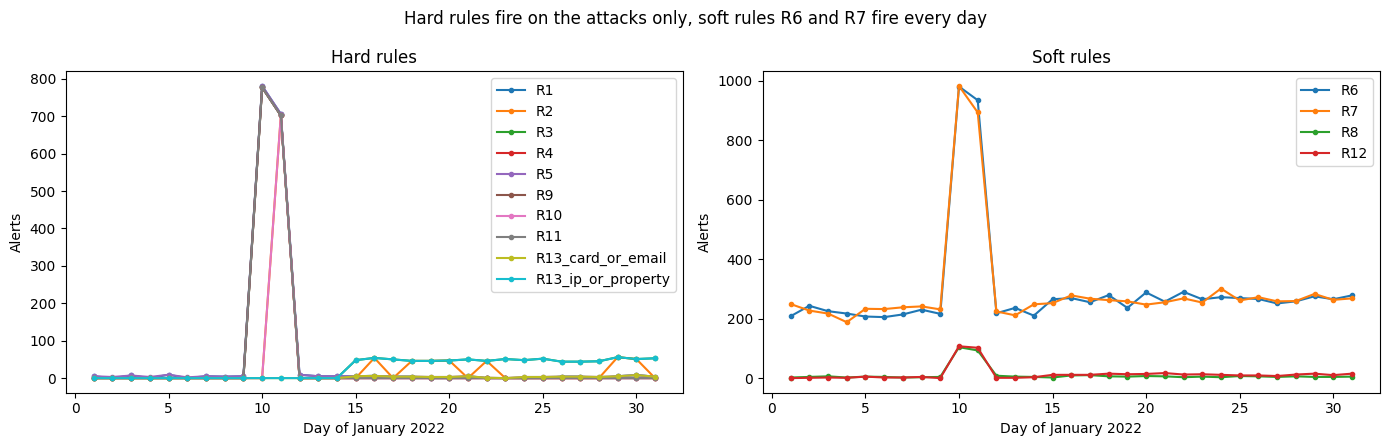

,R1,R2,R3,R4,R5,R9,R10,R11,R13_card_or_email,R13_ip_or_property,R6,R7,R8,R12
day,,,,,,,,,,,,,,
9,5,0,0,0,5,0,0,0,0,0,216,231,4,0
10,781,0,777,777,781,777,0,777,0,0,980,982,104,107
11,706,702,702,702,706,702,702,702,0,0,934,893,93,102
12,9,0,0,0,9,0,0,0,0,0,218,224,8,1
13,5,0,0,0,5,0,0,0,0,0,236,211,5,1
14,5,0,0,0,5,0,0,0,0,0,210,248,4,3
15,5,0,48,0,5,0,0,0,5,48,265,252,2,11
16,6,54,54,0,6,0,0,0,6,54,269,278,9,11


In [38]:
rule_columns = engine.rule_columns("hard") + engine.rule_columns("soft")
alerts_per_day = alerts.groupby("day")[rule_columns].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
alerts_per_day[engine.rule_columns("hard")].plot(ax=axes[0], marker="o", markersize=3)
alerts_per_day[engine.rule_columns("soft")].plot(ax=axes[1], marker="o", markersize=3)
for ax, group in zip(axes, ["Hard rules", "Soft rules"]):
    ax.set_title(group)
    ax.set_xlabel("Day of January 2022")
    ax.set_ylabel("Alerts")
fig.suptitle("Hard rules fire on the attacks only, soft rules R6 and R7 fire every day")
fig.tight_layout()
plt.show()

alerts_per_day.loc[9:16]

**What this shows:** the alerts of each rule per day, hard rules on the left and soft rules on the right. The table gives the numbers for days 9 to 16.

**What we see:** on a normal training day the hard rules R1 and R5 flag 0 to 9 attempts: this is the one card of cluster 2. On day 10 six hard rules flag 777 to 781 attempts each, and on day 11 all eight flag 702 to 706. R2 and R10 only start on day 11, because they look at the declines of the days before. From day 15 on, R3 and the IP part of R13 flag 44 to 56 attempts per day: the grown cluster 2. R2 joins on some of these days only, because it needs at least 2 hard declines from the same IP on the day before. The soft rules R6 and R7 each flag 188 to 301 attempts on every normal day, and 893 to 982 on the two attack days. R8 and R12 are small: most of their training alerts come from days 10 and 11 (197 of the 246 alerts of R8 and 209 of the 231 alerts of R12), which explains their high precision in the table above.

**If it goes up:** a jump in the hard rules is an attack. A slow rise in the soft rules is more often a change in normal traffic, such as more travellers from abroad.

**If it goes down:** fewer alerts and less work, but check that no rule stopped working.

**What we do with it:** the soft rules make several hundred alerts on every normal day, and most of them are good customers. Sections 10 to 12 show how the risk score sorts them.

## 10. Risk model

The model is an Isolation Forest. It needs no labels. It builds 300 small decision trees that cut the data at random points, and it counts how many cuts it takes to separate one attempt from all others. An unusual attempt is alone after a few cuts. A normal attempt needs many, because it sits in a crowd of similar attempts. From this, `RiskModel` makes a **risk score**: the higher the score, the more unusual the attempt. So the score says "how unusual is this attempt", not "is this fraud". It lies between 0 and 1: most normal attempts are below 0.5, and the closer to 1, the easier the attempt is to separate.

We chose this model for three reasons. It needs no label, and we have none that we could train on. It is built from trees, so the features need no scaling and SHAP can explain every score. And it is simple enough to explain to a business team. Each tree is built on a random sample of 256 attempts, the default of scikit-learn. We use 300 trees instead of the default 100: the score is an average over the trees, so more trees make it depend less on the random seed (the seed check at the end of this section shows how much it still moves). We do not tune these settings: tuning needs a label, and tuning on our own label would fit the model to the two attacks that we already know. We also did not compare it with other models. That is out of scope here.

`RiskModel.fit()` learns from the 19 model features of all 36,590 attempts of days 1 to 14. It also sets two cut points on the scores of these days: the top 1% of the scores is the high risk band, the next 4% is medium, and the rest is low (366, 1,464 and 34,760 of the 36,590 training attempts). `RiskModel.score()` then gives every attempt of the month its score and its band.

In [39]:
risk_model = RiskModel(config).fit(alerts[is_train])
scored = risk_model.score(alerts)

pd.DataFrame({
    "risk band": ["medium", "high"],
    "percentile of the training scores": config["model"]["band_percentiles"],
    "starts at risk score": [round(cut, 3) for cut in risk_model.band_cuts],
})

,risk band,percentile of the training scores,starts at risk score
0,medium,95,0.561
1,high,99,0.753


**What this shows:** the two cut points of the risk bands, learned on the scores of days 1 to 14.

**What we see:** an attempt with a risk score of 0.561 or more is in the medium band, and from 0.753 on it is in the high band. Below 0.561 it is low.

**If it goes up:** the training days hold more unusual attempts, so an attempt must be more unusual to leave the low band.

**If it goes down:** the training days are calmer, and the same attempt reaches the medium or high band sooner.

**What we do with it:** the cut points are set like a team sets its capacity: "we can look at the top 5%". They do not use any label. The threshold check at the end of this section shows why this matters.

In [40]:
score_table = evaluator.score_distribution(scored)

pd.crosstab([score_table["split"], score_table["label"]], scored["risk_band"])[["low", "medium", "high"]]

risk_band      low  medium  high
split label                     
test  0      41667     469     0
      1        221     610     0
train 0      34760     281     0
      1          0    1183   366

**What this shows:** the number of attempts in each risk band, for the training and the test days, and for label 0 and label 1 (label of the whole month).

**What we see:**
- **Training days:** 1,464 attempts are medium and 366 are high, together 1,830 or 5.0% of the 36,590 attempts, as the cut points say. 1,549 of these 1,830 are fraud (1,183 medium and all 366 high), and no fraud attempt is low.
- **Test days:** 1,079 attempts are medium (2.5% of 42,967) and none is high. The high band starts at the level of the loud attack of days 10 and 11, and no attempt of the test days is that unusual. Of the 831 fraud attempts, 610 are medium and 221 are low. Of the 42,136 good attempts, 469 are medium (1.1%).

**If it goes up:** more attempts in the medium and high bands mean more unusual traffic and more work for the decision policy.

**If it goes down:** fewer unusual attempts, or a model that no longer fits the traffic.

**What we do with it:** the model alone would not be enough: 221 fraud attempts of the test days are in the low band. The hard rules catch them (section 9). The job of the model in this project is another one: to sort the soft-only alerts, where the rules cannot decide.

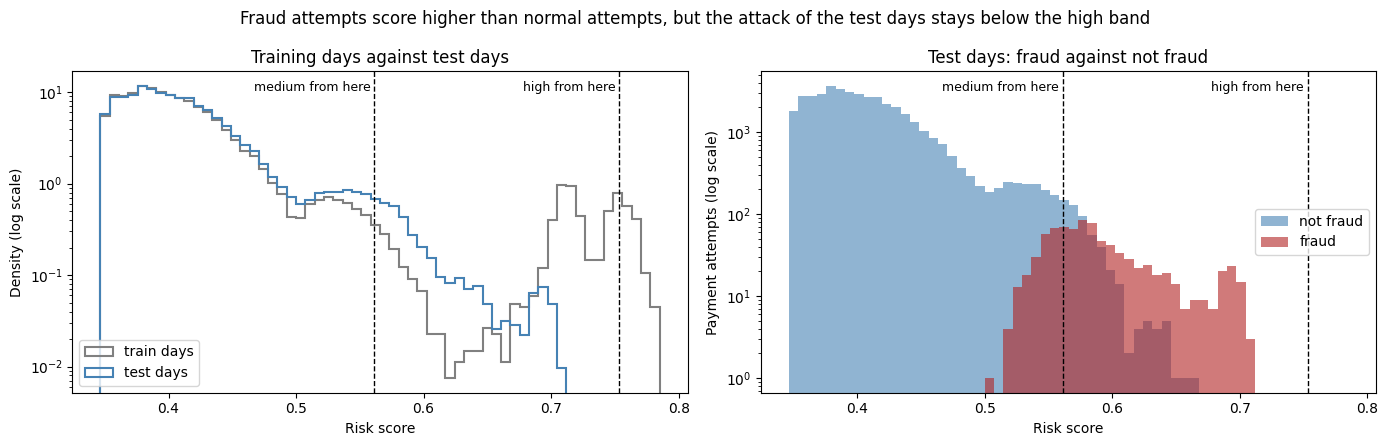

count   mean    std    min    25%    50%    75%    max
split label                                                          
test  0      42136.0  0.409  0.046  0.347  0.376  0.399  0.429  0.661
      1        831.0  0.591  0.044  0.505  0.560  0.581  0.613  0.708
train 0      35041.0  0.406  0.043  0.347  0.375  0.397  0.426  0.649
      1       1549.0  0.730  0.025  0.640  0.711  0.722  0.752  0.785

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
score_range = (score_table["risk_score"].min(), score_table["risk_score"].max())
test_scores = score_table[score_table["split"] == "test"]

for split, color in [("train", "gray"), ("test", "steelblue")]:
    axes[0].hist(score_table.loc[score_table["split"] == split, "risk_score"], bins=60, range=score_range,
                 density=True, histtype="step", linewidth=1.5, color=color, label=f"{split} days")
axes[0].set_title("Training days against test days")
axes[0].set_ylabel("Density (log scale)")

for label, name, color in [(0, "not fraud", "steelblue"), (1, "fraud", "firebrick")]:
    axes[1].hist(test_scores.loc[test_scores["label"] == label, "risk_score"], bins=60, range=score_range,
                 alpha=0.6, color=color, label=name)
axes[1].set_title("Test days: fraud against not fraud")
axes[1].set_ylabel("Payment attempts (log scale)")

for ax in axes:
    for cut, band in zip(risk_model.band_cuts, ["medium", "high"]):
        ax.axvline(cut, color="black", linestyle="--", linewidth=1)
        ax.text(cut, 0.97, f"{band} from here ", transform=ax.get_xaxis_transform(), va="top", ha="right", fontsize=9)
    ax.set_yscale("log")
    ax.set_xlabel("Risk score")
axes[0].legend(loc="lower left")
axes[1].legend(loc="center right")
fig.suptitle("Fraud attempts score higher than normal attempts, but the attack of the test days stays below the high band")
fig.tight_layout()
plt.show()

score_table.groupby(["split", "label"])["risk_score"].describe().round(3)

**What this shows:** the risk scores from `Evaluator.score_distribution()`. Left: the scores of the training days and of the test days. Right: the scores of the test days, for fraud and for normal attempts. The dashed lines are the two cut points. Both charts have a logarithmic scale, so that the small groups stay visible. The table gives the same scores in numbers.

**What we see:** normal attempts look the same on both sides: half of them score below 0.397 on the training days (17,499 of 35,041) and below 0.399 on the test days (20,930 of 42,136). The fraud attempts of the training days score 0.640 to 0.785, far to the right. The fraud attempts of the test days score 0.505 to 0.708: higher than almost all normal attempts (75% of them, 31,504 of 42,136, are below 0.429), but lower than the first attack, and with some overlap. The highest normal attempt of the test days scores 0.661.

**If it goes up:** scores that move to the right mean more unusual traffic. If only the normal attempts move, the model is out of date.

**If it goes down:** fraud that moves to the left looks more like normal traffic, and the model separates it less well.

**What we do with it:** the second attack is quieter than the first, but still more unusual than normal traffic. The next table measures how well the score separates the two groups.

In [42]:
evaluator.score_metric_intervals(scored)

,metric,value,"95% interval, low","95% interval, high"
0,ROC AUC,0.993,0.992,0.993
1,PR AUC,0.725,0.698,0.756


**What this shows:** two numbers that measure the risk score on the test days, each with a 95% interval.
- **ROC AUC:** the chance that a random fraud attempt has a higher score than a random normal attempt. 0.5 is a coin flip, 1.0 is perfect.
- **PR AUC:** this number looks only at the top of the ranking: if we go down the list from the highest score, how much of what we find is fraud? It is the harder test when fraud is rare. Only 1.9% of the test attempts are fraud (831 of 42,967), so a random score would get about 0.02.

The interval comes from a bootstrap: we draw the test attempts again 500 times, with repeats, and measure each draw. 95% of the draws fall inside the interval.

**What we see:** the ROC AUC is 0.993 (interval 0.992 to 0.993) and the PR AUC is 0.725 (interval 0.698 to 0.756). Both intervals are narrow, so the numbers do not hang on a few attempts of these 17 days.

**If it goes up:** the score ranks fraud above normal attempts more cleanly.

**If it goes down:** fraud and normal attempts mix more. A PR AUC that falls while the ROC AUC stays high means that the very top of the list fills with good customers.

**What we do with it:** three limits belong to these numbers. First, the ROC AUC is helped by the design of the label (section 7). Second, the interval shows the effect of which attempts are in the test days, not the effect of the random seed of the model. The seed check at the end of this section fits the model with 9 seeds: the ROC AUC stays at about 0.99, but the PR AUC goes from 0.62 to 0.79. We keep seed 42 and do not pick a seed by its test result. Third, the bootstrap treats the attempts as independent, but all fraud of the test days comes from one attack. We tested the model on one attack, not on 831 separate cases, so the real uncertainty is larger than these intervals.

In [43]:
evaluator.new_pattern_result(scored)

,new-pattern attempts,top share of test scores (%),new-pattern attempts in it (%)
0,766,5.0,97.5
1,766,1.0,35.1


**What this shows:** the hardest test for the model. A new-pattern attempt is a fraud attempt of the test days whose card was first seen on day 15 or later. No list of known cards can catch it. The table says how many of these attempts are among the highest 5% and the highest 1% of all risk scores of the test days.

**What we see:** 766 of the 831 fraud attempts of the test days use a new card. 97.5% of them (747 of 766) are in the top 5% of the 42,967 test scores (a score of 0.530 or more), and 35.1% (269 of 766) are in the top 1% (0.588 or more). The model never saw these cards, and on the training days this attack was one single card (section 7). It still finds the new attempts unusual. Section 11 shows why: they are costly, short, last-minute stays, and many of them come from the same IP on the same day.

**If it goes up:** the model ranks new attacks even closer to the top.

**If it goes down:** new attacks hide better among normal attempts. Below about 50% in the top 5%, the model would miss most of a new attack.

**What we do with it:** this is the reason to add a model to the rules: it does not need to know a card or an email to find an attempt unusual. Read the two numbers together: the model ranks the new attack above almost all normal traffic, but not at the very top. How much of it gets friction depends on where the cut point is.

In [44]:
decisions = DecisionPolicy(config).decide(scored)

evaluator.threshold_check(decisions, train_labeled["label"], risk_model.band_cuts[0])

,cut,risk score,new-pattern attempts at or above it (%)
0,fraud-based cut,0.700,0.0
1,band cut (95th percentile of all training scores),0.561,71.1


**What this shows:** a check of how we set the cut point. The check needs to know which attempts have a rule alert. `DecisionPolicy.decide()` adds this, and section 12 looks at its actions. The table compares two ways to set the cut point for the medium band:
- **fraud-based cut:** we take the fraud alerts of the training days, sort them by risk score and set the cut so that the alerts above it hold 95% of their value. This is the usual way when labels exist.
- **band cut:** our way, the 95th percentile of all training scores, without any label.

For both, the table gives the share of the 766 new-pattern attempts at or above the cut.

**What we see:** the fraud-based cut is 0.700, and 0.0% of the new-pattern attempts reach it (0 of 766). The band cut is 0.561, and 71.1% reach it (545 of the 766). This share is lower than the 97.5% of the table before, because the band cut comes from the training days, which hold the loud attack. The top 5% of the test scores alone starts lower.

**If it goes up:** a cut that more new-pattern attempts reach would have caught more of the new attack.

**If it goes down:** the cut is too high for the new attack.

**What we do with it:** a cut point that is tuned on the known fraud fits the known fraud. The attack of days 10 and 11 was loud, so its cut is high, and the quieter attack of the test days stays below it. A cut point from the whole score distribution does not depend on how extreme the last attack was. This is why the risk bands come from percentiles.

**Known limit:** the percentile cut is not free of the last attack either. It depends on its size. The band table above shows that 1,549 of the 1,830 training attempts at or above the cut are attack attempts, so the cut sits about where the first attack ends. With a smaller attack in the training days, the cut would be lower: more of a new attack would reach it, and more good customers too. In a live system we would set the bands on the traffic without hard alerts, which is the traffic that the model decides on, and choose the percentile by the capacity for extra checks. Section 13 tests other cut points.

In [45]:
seed_rows = []
for seed in [42, 0, 1, 2, 3, 4, 5, 6, 7]:
    seed_config = copy.deepcopy(config)
    seed_config["model"]["random_state"] = seed
    seed_model = RiskModel(seed_config).fit(alerts[is_train])
    seed_scored = seed_model.score(alerts)
    new_pattern_scores = evaluator.new_pattern_attempts(seed_scored)["risk_score"]
    seed_metrics = evaluator.score_metrics(seed_scored[~is_train])
    seed_rows.append({
        "seed": seed,
        "ROC AUC": round(seed_metrics["ROC AUC"], 3),
        "PR AUC": round(seed_metrics["PR AUC"], 3),
        "band cut": round(seed_model.band_cuts[0], 3),
        "new-pattern attempts at or above the band cut (%)": round(100 * (new_pattern_scores >= seed_model.band_cuts[0]).mean(), 1),
    })
pd.DataFrame(seed_rows)

,seed,ROC AUC,PR AUC,band cut,new-pattern attempts at or above the band cut (%)
0,42,0.993,0.725,0.561,71.1
1,0,0.995,0.778,0.558,80.4
2,1,0.990,0.650,0.567,61.2
3,2,0.993,0.735,0.554,73.2
4,3,0.993,0.719,0.562,71.7
5,4,0.994,0.748,0.561,77.5
6,5,0.989,0.618,0.555,58.9
7,6,0.993,0.721,0.567,76.9
8,7,0.995,0.787,0.554,83.2


**What this shows:** the seed check. The Isolation Forest picks its samples and its cut points at random, and the seed fixes these random choices. We fit the model again with 9 seeds (42, the seed in use, and 0 to 7) on the same training days, and measure each fit on the test days: ROC AUC, PR AUC, the band cut (95th percentile of the training scores) and the share of the 766 new-pattern attempts at or above it.

**What we see:** the ROC AUC stays between 0.989 and 0.995. The PR AUC moves from 0.618 (seed 5) to 0.787 (seed 7), and the share of new-pattern attempts at or above the band cut from 58.9% (451 of 766, seed 5) to 83.2% (637 of 766, seed 7). The band cut itself moves only a little, from 0.554 to 0.567. Seed 42 is in the middle of the range: PR AUC 0.725 and 71.1% (545 of 766).

**If it goes up:** a wider spread between the seeds means that one run says less, and the numbers should be read as a range.

**If it goes down:** the model gives the same answer whatever the seed.

**What we do with it:** we keep seed 42 and report the range. Picking the seed with the best test result would be tuning on the test days.

## 11. Why did an attempt get its score? (SHAP)

A score alone does not help an analyst. SHAP is a method that splits the score of one attempt into the part of each feature: how much did this feature push the risk up or down? `RiskModel.explain()` computes it, and `RiskModel.global_importance()` gives the average over many attempts. SHAP learns nothing. It only asks the fitted model, so we can use it on the test days.

For an Isolation Forest, SHAP explains the number of cuts that the trees need to separate the attempt (the path length). Fewer cuts mean a more unusual attempt. We flip the sign and call the result **risk contribution**: a positive value raises the risk.

8,090 attempts with a rule alert on the test days: {'soft only': 7259, 'hard': 831}


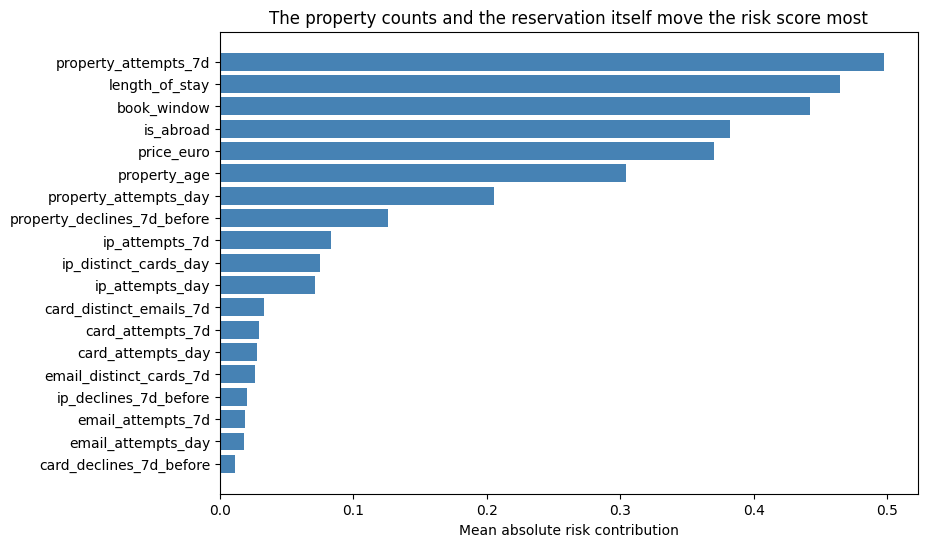

,feature,mean absolute risk contribution
0,property_attempts_7d,0.498
1,length_of_stay,0.465
2,book_window,0.442
3,is_abroad,0.382
4,price_euro,0.370
5,property_age,0.304
6,property_attempts_day,0.205
7,property_declines_7d_before,0.126


In [46]:
test_decisions = decisions[decisions["day"] > train_last_day]
test_alerts = test_decisions[test_decisions["alert_type"] != "none"]
print(f"{len(test_alerts):,} attempts with a rule alert on the test days:", test_alerts["alert_type"].value_counts().to_dict())

importance = risk_model.global_importance(test_alerts)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance["feature"][::-1], importance["mean absolute risk contribution"][::-1], color="steelblue")
ax.set_title("The property counts and the reservation itself move the risk score most")
ax.set_xlabel("Mean absolute risk contribution")
plt.show()

importance.head(8)

**What this shows:** the global view. For a random sample of 2,000 of the 8,090 attempts with a rule alert on the test days, we take the size of the risk contribution of each feature and average it. A long bar means that the feature often moves the score, up or down.

**What we see:** property_attempts_7d moves the score most (0.498), then length_of_stay (0.465), book_window (0.442), is_abroad (0.382), price_euro (0.370) and property_age (0.304). The card and email counts are at the bottom, with 0.033 or less.

**If it goes up:** the feature gains weight in the score. If one feature takes over, the model depends too much on it.

**If it goes down:** the feature matters less for these alerts.

**What we do with it:** on the test days almost every card and email is used once, so the counts of cards and emails cannot tell the alerts apart. The model leans on the property counts and on the reservation itself. This is good news for the known limit of section 7: these features do not use the links of the label.

### Three examples

A waterfall plot explains one attempt. How to read it:
- Start at the bottom, at the value E[f(X)]. This is the average result for the attempts that the model learned from.
- Each bar is one feature. The gray number in front of its name is the value of the feature for this attempt. A red bar to the right raises the risk, a blue bar to the left lowers it.
- The top value f(x) is the result for this attempt. The further right it ends, the more unusual the attempt.

The numbers on the axis are the flipped path lengths, so they are negative. They rank the attempts in the same order as the risk score, but they are not the same number.

Each example is chosen at random, with seed 42, from its group.

,day,label,alert_type,risk_score,risk_band,value_band,hybrid_action
79219,18,1,hard,0.631,medium,high,block


Rules that fired: ['R2', 'R3', 'R13_ip_or_property', 'R6', 'R7', 'R12']


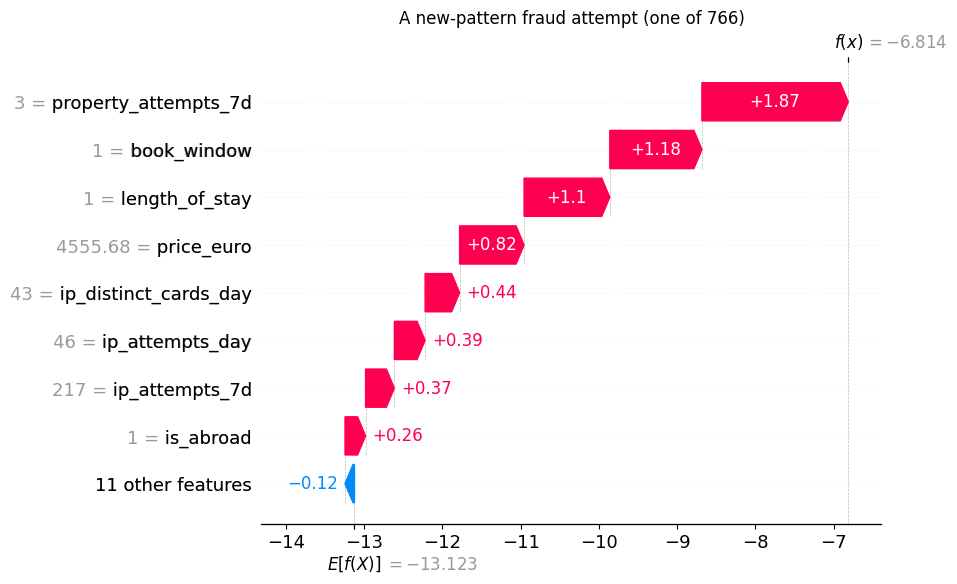

In [47]:
example_facts = ["day", "label", "alert_type", "risk_score", "risk_band", "value_band", "hybrid_action"]
soft_only = test_decisions[test_decisions["alert_type"] == "soft only"]


def show_example(title: str, candidates: pd.DataFrame) -> None:
    """Pick one attempt at random, show its facts and its fired rules, and draw its waterfall plot."""
    example = candidates.sample(1, random_state=config["model"]["random_state"])
    display(example[example_facts].round(3))
    print("Rules that fired:", [rule for rule in rule_columns if example[rule].iloc[0]])
    shap.plots.waterfall(risk_model.explain(example)[0], max_display=9, show=False)
    plt.title(f"{title} (one of {len(candidates):,})")
    plt.show()


show_example("A new-pattern fraud attempt", evaluator.new_pattern_attempts(decisions))

**What this shows:** one of the 766 new-pattern fraud attempts: its facts, the rules that fired and its waterfall plot.

**What we see:** an attempt of day 18 with a risk score of 0.631 (medium band). The plot starts at -13.123 and ends at -6.814, far to the right. The largest pushes come from the reservation: the property had 3 attempts in 7 days (+1.87), the book window is 1 day (+1.18), the stay is 1 night (+1.10) and the price is 4,556 EUR (+0.82). The IP adds less: 43 different cards (+0.44) and 46 attempts on that day (+0.39). No card or email feature is among the largest bars, because the card and the email are new. Three hard rules fired as well (R2, R3 and the IP part of R13), next to the soft rules R6, R7 and R12, so the action is block.

**If it goes up:** longer red bars mean a more unusual attempt.

**If it goes down:** an attack that books further ahead, for longer stays and at normal prices would lose these red bars and hide better.

**What we do with it:** the plot tells an analyst in one look why the attempt is unusual: a costly last-minute stay of one night, from an IP that used 43 cards on that day.

,day,label,alert_type,risk_score,risk_band,value_band,hybrid_action
42698,31,0,soft only,0.437,low,low,allow


Rules that fired: ['R7']


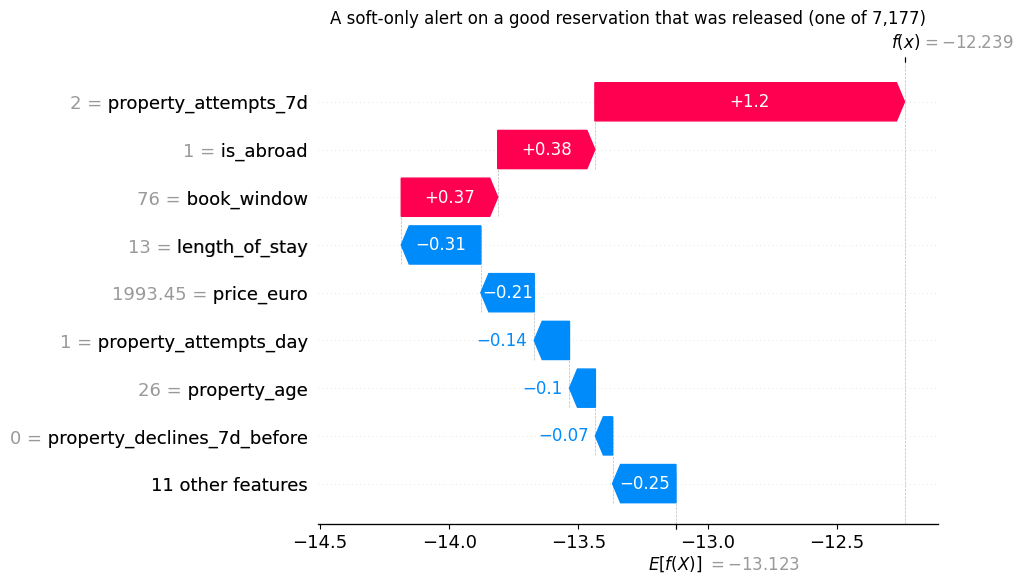

In [48]:
is_released = ~soft_only["hybrid_action"].isin(FRICTION_ACTIONS)
show_example("A soft-only alert on a good reservation that was released", soft_only[(soft_only["label"] == 0) & is_released])

**What this shows:** one of the 7,177 good reservations of the test days that had only a soft alert and were released by the hybrid system.

**What we see:** an attempt of day 31 with a language mismatch (rule R7). With rules only, this customer gets an extra check. Its risk score is 0.437 (low band), and the plot ends at -12.239, close to the start. The property had 2 attempts in 7 days (+1.20) and is abroad (+0.38), but the stay of 13 nights (-0.31), the price of 1,993 EUR (-0.21) and the other features pull the risk back down. The action is allow.

**If it goes up:** more red bars would move the attempt to the medium band and to an extra check.

**If it goes down:** an even more normal reservation.

**What we do with it:** this is the typical case that the model is for: a soft rule flags a customer who only uses a site in another language, and everything else about the reservation is normal.

,day,label,alert_type,risk_score,risk_band,value_band,hybrid_action
27684,15,0,soft only,0.57,medium,low,step_up


Rules that fired: ['R6', 'R7']


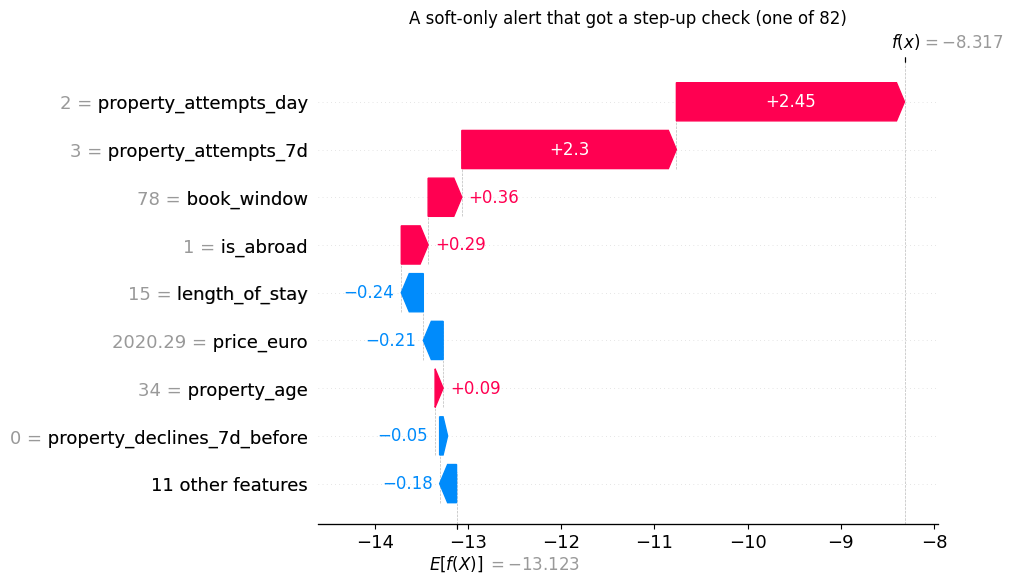

In [49]:
show_example("A soft-only alert that got a step-up check", soft_only[soft_only["hybrid_action"] == "step_up"])

**What this shows:** one of the 82 soft-only alerts of the test days that still got an extra check (step_up) in the hybrid system.

**What we see:** a good reservation of day 15 with a card country mismatch (R6) and a language mismatch (R7). Its risk score is 0.570, just above the cut point of 0.561, so it is in the medium band. Two features carry almost the whole push: the property had 2 attempts on that day (+2.45) and 3 in 7 days (+2.30). The book window of 78 days, the stay of 15 nights and the price of 2,020 EUR are all normal.

**If it goes up:** more attempts at the same property would push the score further.

**If it goes down:** without the other attempts at that property, the two large red bars would be gone, and the reservation would look normal.

**What we do with it:** this is a false alert, and the plot shows where it comes from: the model finds a property with a few reservations in one week unusual, because most properties have only one. That is a weak spot of the model in this data. A popular hotel is not a risk. The cost is small, 82 extra checks in 17 days, and section 13 puts a number on it.

## 12. Decisions

`DecisionPolicy.decide()` turns the rule alerts and the risk score into one action per attempt. The actions, from light to strong, are: allow, allow_and_monitor (allow, but keep an eye on it), step_up (an extra check for the customer), manual_review (an analyst looks at it) and block. **Friction** means step_up, manual_review or block: the customer or an analyst has extra work.

The policy decides twice, so that we can compare two setups:
- **hybrid:** if a hard rule fired, the strongest action of the hard rules counts. If only soft rules fired, the risk band and the value band decide. Without any alert the attempt is allowed.
- **rules only:** the same, but every attempt with only soft alerts gets a step-up check. This is the system without the model. A rule set without a score cannot tell one soft alert from another: it can act on all of them or on none. Acting on none means that the soft rules are switched off, and section 13 also shows that case.

Section 10 already called `decide()`, so the table `decisions` exists. Here we look at its actions on the test days.

In [50]:
print("Attempts of the test days by alert type:", test_decisions["alert_type"].value_counts().to_dict())

action_counts = pd.DataFrame({
    "rules only": test_decisions["rules_only_action"].value_counts(),
    "hybrid": test_decisions["hybrid_action"].value_counts(),
})
action_counts.reindex(config["decision"]["action_order"]).fillna(0).astype(int)

Attempts of the test days by alert type: {'none': 34877, 'soft only': 7259, 'hard': 831}


,rules only,hybrid
allow,34877,39600
allow_and_monitor,0,2454
step_up,7259,82
manual_review,450,450
block,381,381


**What this shows:** the number of attempts per action on the test days, for both setups. The line above the table says how many attempts have no alert, only soft alerts, or a hard alert.

**What we see:** of the 42,967 attempts, 34,877 have no alert, 7,259 have only soft alerts and 831 have a hard alert. The 831 hard alerts get the same actions in both setups: 450 manual reviews and 381 blocks. The 381 blocks are the attempts where R2 (346) or the card part of R13 (65) fired, 30 of them both. The other 450 only fired R3 and the IP part of R13, whose action is a manual review. The difference is in the 7,259 soft-only alerts. With rules only, all of them get a step-up check (3,789 fired R6, 3,760 R7, 46 R8 and 28 R12; 364 fired two of these rules). In the hybrid system only 82 do: 4,723 are allowed and 2,454 are allowed and monitored.

**If it goes up:** more step-up checks mean more customers who must prove who they are, and some of them will give up the reservation.

**If it goes down:** fewer checks. That is only good if the fraud value caught stays the same (section 13).

**What we do with it:** the model takes 7,177 step-up checks away in 17 days (7,259 minus 82), about 422 per day (7,177 divided by 17). The next table shows how the policy sorts the soft-only alerts.

In [51]:
print("Action of the policy for a soft-only alert, by value band (rows) and risk band (columns)")
display(pd.DataFrame(config["decision"]["soft_policy"]).T)

print("Soft-only alerts of the test days in each cell")
pd.crosstab(soft_only["value_band"], soft_only["risk_band"]).reindex(
    index=["low", "medium", "high"], columns=["low", "medium", "high"], fill_value=0)

Action of the policy for a soft-only alert, by value band (rows) and risk band (columns)


,low,medium,high
high_value,allow_and_monitor,step_up,manual_review
other_value,allow,step_up,block


Soft-only alerts of the test days in each cell


risk_band,low,medium,high
value_band,,,
low,2320,29,0
medium,2403,29,0
high,2454,24,0


**What this shows:** the first table is the policy for soft-only alerts from `config.yaml`: one row for high-value reservations and one for the others, one column per risk band. The second table counts the soft-only alerts of the test days per value band and risk band.

**What we see:** 7,177 of the 7,259 soft-only alerts are in the low risk band. The 4,723 of them with a low or medium value (2,320 + 2,403) are allowed, and the 2,454 with a high value are allowed and monitored, because a mistake costs more there. 82 alerts are in the medium risk band (29, 29 and 24), and all of them get a step-up check. No soft-only alert is in the high risk band, so the two strongest cells of the policy (manual review and block) are never used on the test days. The policy is stricter with the customer where a mistake is cheap, and more careful where it is costly: at high risk a cheaper reservation is blocked, but a high-value one goes to an analyst, because a wrong block there loses more revenue than a review costs.

**If it goes up:** more alerts in the medium or high band mean more friction. If many good customers land there, the cut points are too low.

**If it goes down:** more alerts are released. If fraud is among them, the cut points are too high.

**What we do with it:** one fact matters for the next section. On the test days none of the 7,259 soft-only alerts is fraud: every fraud attempt also has a hard alert. So here the model only has to release good customers, and the test cannot show how it would treat fraud that the hard rules miss.

In [52]:
split_names = decisions["day"].gt(train_last_day).map({False: "training days", True: "test days"})
print("Properties with a held payout:", decisions.loc[decisions["hold_payout"], "hotel_id"].nunique())

pd.crosstab(split_names, decisions["hold_payout"]).rename_axis(index=None, columns="hold_payout")

Properties with a held payout: 7


hold_payout,False,True
test days,42967,0
training days,35111,1479


**What this shows:** the attempts for which the payout to the property is held. Three hard rules set this flag: R4 (new property and short book window), R9 (many attempts at one property on one day) and R10 (many earlier declines at one property).

**What we see:** 1,479 attempts have a held payout, at 7 properties, all on the training days. These are the new listings of the attack of days 10 and 11. On the test days no payout is held: the second attack goes to older properties with one or a few reservations each, and none of the three rules fires.

**If it goes up:** more properties look like fake listings, and more money is kept back until the owner is checked.

**If it goes down:** fewer such properties, or attackers who spread their reservations over many real properties, as the second attack does.

**What we do with it:** holding the payout is the last chance to stop a loss after a payment was authorised. Section 14 lists the properties.

## 13. Evaluation

The rules are the production rule set, designed on all available history. The Isolation Forest is a second signal on top of them. Everything the ML layer learns (the model, the risk bands and the price cut points) comes from days 1 to 14 only, and the comparison runs on days 15 to 31 with the same rules on both sides.

`Evaluator.compare_setups()` measures both setups on the 17 test days. "Fraud" always means label 1 of the whole-month label (section 7). A **good reservation** is a test-day attempt with label 0.

In [53]:
def with_thousands(table: pd.DataFrame) -> pd.DataFrame:
    """Show the numbers of the two setups with thousands separators, so that they are easy to read."""
    return table.assign(**{setup: table[setup].map("{:,.1f}".format) for setup in ["rules only", "hybrid"]})


with_thousands(evaluator.compare_setups(decisions))

,metric,rules only,hybrid
0,friction actions,"8,090.0",913.0
1,false positive share (%),89.7,9.0
2,good reservations with friction,"7,259.0",82.0
3,"good reservations with friction, share of all good reservations (%)",17.2,0.2
4,good reservations with friction (EUR),"19,008,758.2","208,706.6"
5,fraud value caught (EUR),"3,134,375.6","3,134,375.6"
6,"fraud value caught, share of the rules-only value (%)",100.0,100.0
7,authorised part of the fraud value caught (EUR),"2,631,248.4","2,631,248.4"
8,manual reviews per day,26.5,26.5
9,precision per attempt (%),10.3,91.0


**What this shows:** the main comparison: one row per metric, one column per setup.
- **False positive share:** of all friction actions, the share that fell on good reservations.
- **Fraud value caught:** the value of the fraud attempts that got friction.
- **Precision:** the share of the flagged units that are fraud. **Recall:** the share of the fraud units that are flagged. A unit is an attempt, a card, an IP or a property. A card, IP or property is fraud if one of its test-day attempts is fraud, and flagged if one of them got friction.

**What we see:**
- **Friction:** 8,090 actions with rules only, 913 with the hybrid system. Both include the 831 attempts with a hard alert: all 831 fired R3 and the IP part of R13, 346 also fired R2, 65 also R5 and the card part of R13, and 49 also R1. Rules only adds all 7,259 attempts with only soft alerts (3,789 fired R6, 3,760 R7, 46 R8 and 28 R12; 364 fired two of them). The hybrid system adds only the 82 of them in the medium risk band (45 fired R6, 41 R7 and 1 R12; 5 fired two of them).
- **False positive share:** 89.7% (7,259 of 8,090) against 9.0% (82 of 913). This is 100% minus the precision per attempt. With rules only, 7,259 good reservations get friction, worth 19.0 million EUR (the sum of their price_euro). With the hybrid system it is 82, worth 0.2 million EUR.
- **Share of all good reservations:** 17.2% of the 42,136 good reservations get friction with rules only (7,259), and 0.2% with the hybrid system (82). A textbook calls this number the false positive rate.
- **Fraud value caught:** 3.13 million EUR in both setups (the price_euro of all 831 fraud attempts of the test days), so the hybrid system keeps 100% of what the rules catch. The target in the project brief is at least 95% of what the rules alone catch. The payment provider authorised 2.63 million EUR of it (707 of the 831 attempts) and declined the rest anyway, so 2.63 million EUR is the money that was really at risk.
- **Manual reviews:** 26.5 per day in both setups (450 reviews in 17 test days).
- **Precision per attempt:** 10.3% (831 fraud attempts of 8,090 flagged) against 91.0% (831 of 913). Per card it is 9.6% (767 fraud cards of 8,026 flagged cards) against 90.3% (767 of 849), and per property 7.9% (590 of 7,459) against 88.7% (590 of 665). Recall is 100% everywhere (all 831 fraud attempts, 767 fraud cards, 1 fraud IP and 590 fraud properties are flagged).
- **Precision per IP** is 0.0% and 1.2%. This number says nothing about the quality of the system. All fraud of the test days comes from one single IP, so there is exactly one fraud IP. Every good customer with friction has an own IP. The precision per IP is therefore 1 divided by the number of IPs with friction: about 7,260 with rules only and 83 with the hybrid system.
- **Soft-only alerts:** 427 per day (7,259 in 17 days). With rules only all of them get friction, with the hybrid system 4.8 per day (82 in 17 days).

**If it goes up:** a higher false positive share means more good customers with extra checks or blocks. We can lose reservations and spend more time on support. It can also mean that customer behaviour changed and the model needs retraining.

**If it goes down:** fewer good customers are bothered. This is only good news if the fraud value caught does not drop at the same time, so always read the two numbers together.

**What we do with it:** this is the main goal of the project: fewer false positives without losing fraud. Read the fraud side with care. Recall is 100% in both setups because every fraud attempt of the test days has a hard alert, and the hard rules were designed with the whole history in view. The hard rules alone would give 831 friction actions, all on fraud. So on these test days the soft rules catch no extra fraud in either setup: with rules only they cost 7,259 extra checks, and with the hybrid system 82. The soft rules are a safety net for attacks that the hard rules do not see, and the model makes this net cheap. The comparison proves this gain for the good customers. It does not prove that the model would stop fraud that the hard rules miss. The stress test at the end of this section looks at that case.

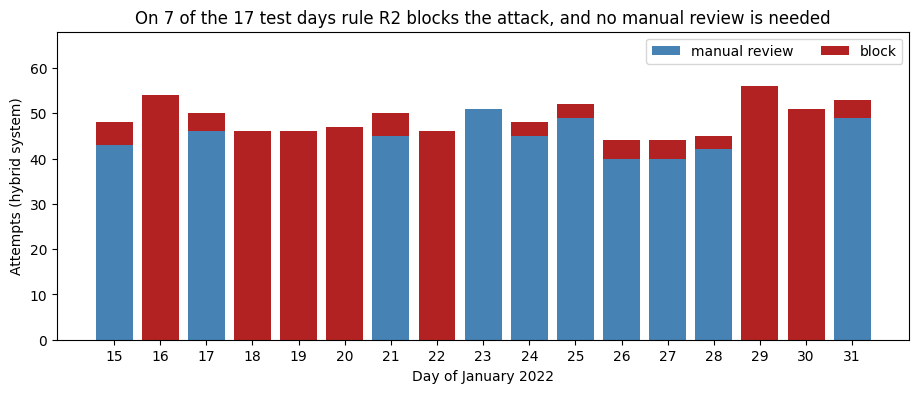

day,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
rules only,43,0,46,0,0,0,45,0,51,45,49,40,40,42,0,0,49
hybrid,43,0,46,0,0,0,45,0,51,45,49,40,40,42,0,0,49


In [54]:
reviews = evaluator.reviews_per_day(decisions)
blocks = (test_decisions["hybrid_action"] == "block").groupby(test_decisions["day"]).sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(reviews["day"], reviews["hybrid"], color="steelblue", label="manual review")
ax.bar(reviews["day"], blocks.values, bottom=reviews["hybrid"], color="firebrick", label="block")
ax.set_title("On 7 of the 17 test days rule R2 blocks the attack, and no manual review is needed")
ax.set_xlabel("Day of January 2022")
ax.set_ylabel("Attempts (hybrid system)")
ax.set_xticks(reviews["day"])
ax.set_ylim(0, 68)
ax.legend(loc="upper right", ncol=2)
plt.show()

reviews.set_index("day").T

**What this shows:** the manual reviews per test day from `Evaluator.reviews_per_day()`, for both setups. The chart adds the blocked attempts of the hybrid system on top, so each bar is the hard alerts of one day.

**What we see:** both setups have the same reviews, because all of them come from hard rules. The average of 26.5 per day (450 reviews in 17 days) hides two kinds of days. On 10 days there are 40 to 51 reviews. On 7 days (16, 18, 19, 20, 22, 29 and 30) there are none: rule R2 fires when the IP had at least 2 hard declines on the day before, and then it blocks every attempt from that IP. On these days the 46 to 56 attack attempts are blocked and need no analyst.

**If it goes up:** more work for the analysts. A team that can do 30 reviews per day would not keep up on the busy days.

**If it goes down:** less work, or more attempts that are blocked without a human look.

**What we do with it:** the team should plan for the busy days, about 40 to 51 reviews, not for the average. A block is also not free: the customer gets no second chance, so a rule that blocks must stay as precise as R2 is here.

### Do the results depend on the split day?

Day 14 as the last training day is a design choice. `FraudPipeline.split_day_sensitivity()` runs the whole pipeline again with day 10 and day 18. Each run learns everything again from its own training days: the price limits, the hotlist of rule R13, the model and the risk bands.

In [55]:
pipeline = FraudPipeline()

pipeline.split_day_sensitivity()

,training days,test days,clusters in the training days,fraud attempts on the test days,ROC AUC,PR AUC,"false positive share, rules only (%)","false positive share, hybrid (%)","fraud value caught, hybrid (% of rules only)"
0,1 to 10,11 to 31,2,1556,0.997,0.931,85.2,13.4,100.0
1,1 to 14,15 to 31,2,831,0.993,0.725,89.7,9.0,100.0
2,1 to 18,19 to 31,2,633,1.000,0.999,89.9,25.7,100.0


**What this shows:** one row per split day, with the same key numbers. Known limit: each row has other test days, so the rows show if the story holds, not which split day is best.

**What we see:**
- **What stays the same:** the hybrid system catches 100% of the fraud value in all three runs (5,259,398 EUR with day 10, 3,134,376 EUR with day 14 and 2,402,323 EUR with day 18). The rules alone have a false positive share of 85.2% to 89.9% (8,977 of 10,533 friction actions with day 10, 7,259 of 8,090 with day 14 and 5,647 of 6,280 with day 18), and the hybrid system is far below that in every run: 13.4% (240 of 1,796), 9.0% (82 of 913) and 25.7% (219 of 852). The ROC AUC is 0.993 or higher.
- **What moves:** the PR AUC goes from 0.725 to 0.999, so this number depends a lot on which attack days fall into the test days. The false positive share of the hybrid system is clearly higher with day 18.

**If it goes up:** a larger gap between the rows would mean that the result depends on which days we happened to pick.

**If it goes down:** rows that look alike mean a stable result.

**What we do with it:** the main story holds for all three split days. The next cell looks at why the run with day 18 has more false positives.

In [56]:
late_split = pipeline.run(train_last_day=18, save_outputs=False)

display(with_thousands(late_split.comparison.head(3)))
late_split.rule_summary[["rule", "alerts (test days)", "fraud (test days)", "not fraud (test days)"]].iloc[8:10]

,metric,rules only,hybrid
0,friction actions,"6,280.0",852.0
1,false positive share (%),89.9,25.7
2,good reservations with friction,"5,647.0",219.0


,rule,alerts (test days),fraud (test days),not fraud (test days)
8,R13_card_or_email,46,46,0
9,R13_ip_or_property,758,633,125


**What this shows:** the run with day 18 as the last training day: the first rows of its comparison table, and the two rows of rule R13 in its rule summary.

**What we see:** the hybrid system gives friction to 219 good reservations in this run. 125 of them come from one place: the IP and property part of the hotlist. With four more training days, the hotlist holds many more properties of the second attack. These are older properties that good customers book too, and each of their reservations now goes to manual review. The card and email part of the hotlist makes no false alert.

**If it goes up:** the longer the second attack runs, the more real properties land on the hotlist, and the more good customers get a manual review.

**If it goes down:** a hotlist with fewer properties hits fewer good customers.

**What we do with it:** this is a weak spot of rule R13, and the main run with day 14 does not show it. A card, an email or an IP of an attack can go on a hotlist. A property that fraudsters only used as a destination should not be treated in the same way as a fake listing. Section 15 takes this up as a recommendation.

### What if the hard rules miss the attack?

On the test days the hard rules catch every fraud attempt, because the whole attack comes from one IP (rule R3 and the IP part of R13). An attacker can change this with little effort. So we ask: what would the two setups do if every fraud attempt came from its own IP?

`FraudPipeline.run(new_ip_per_fraud_attempt=True)` runs the whole pipeline again on changed data: every fraud attempt gets a new IP. The features, the hotlist, the model and the risk bands are all built again from the changed data. Only the label stays the one of the real data, so we still know which attempts are fraud. This is a what-if test on data that we changed ourselves, not a result on the real data.

In [57]:
stress = pipeline.run(save_outputs=False, new_ip_per_fraud_attempt=True)
stress_test_days = stress.decisions[stress.decisions["day"] > train_last_day]
stress_fraud = stress_test_days[stress_test_days["label"] == 1]

print("Stress test: fraud attempts of the test days by alert type (rows) and hybrid action (columns)")
display(pd.crosstab(stress_fraud["alert_type"], stress_fraud["hybrid_action"]))

with_thousands(stress.comparison.iloc[[0, 1, 2, 5, 6]])

Stress test: fraud attempts of the test days by alert type (rows) and hybrid action (columns)


hybrid_action,allow,allow_and_monitor,block,step_up
alert_type,,,,
hard,0,0,65,0
soft only,2,584,0,180


,metric,rules only,hybrid
0,friction actions,"8,090.0",325.0
1,false positive share (%),89.7,24.6
2,good reservations with friction,"7,259.0",80.0
5,fraud value caught (EUR),"3,134,375.6","825,264.3"
6,"fraud value caught, share of the rules-only value (%)",100.0,26.3


**What this shows:** the stress test. The first table counts the 831 fraud attempts of the test days by their alert type and by the action of the hybrid system. The second table has five rows of the main comparison, now for the changed data.

**What we see:**
- **The hard rules lose the attack.** Only 65 fraud attempts still have a hard alert: the one card that comes back. The other 766 have only soft alerts.
- **Rules only** still puts friction on 100% of the fraud value, because every soft alert gets an extra check. The price is the same as before: 7,259 good reservations with friction.
- **The hybrid system** gives an extra check to 180 of the 766 attempts. It releases 586: 584 are allowed and monitored, because they are high-value reservations, and 2 are allowed. It catches 825,264 EUR, 26.3% of the fraud value (825,264 of 3,134,376 EUR). The target of the project brief is 95%. Only 80 good reservations get friction: its 325 friction actions are 245 fraud attempts and 80 good reservations, a false positive share of 80 / 325 = 24.6%.

**If it goes up:** a higher share of fraud value caught means that the model alone stops more of an attack that the hard rules do not see.

**If it goes down:** more of such an attack gets through.

**What we do with it:** this is the weak spot of the system as it is set up now, and the main test days cannot show it. The model does rank these attempts high (section 10), but the cut point for the medium band is too high for a quiet attack: it sits where the loud attack of days 10 and 11 ends. The 584 monitored reservations would get a second look before the payout, but we did not test that step. The next table asks what other cut points would do.

In [58]:
print("Real data")
display(evaluator.cut_point_tradeoff(decisions, risk_model.band_cuts[0]))

print("Stress test: a new IP for every fraud attempt")
evaluator.cut_point_tradeoff(stress.decisions, stress.band_cuts[0])

Real data


,cut point,risk score,fraud value caught (%),good reservations with friction per day,false positive share (%)
0,cut point in use,0.561,100.0,4.8,9.0
1,percentile 80 without hard alerts,0.433,100.0,100.5,67.3
2,percentile 90 without hard alerts,0.458,100.0,54.7,52.8
3,percentile 95 without hard alerts,0.490,100.0,26.9,35.5
4,percentile 97 without hard alerts,0.524,100.0,16.6,25.4
5,percentile 99 without hard alerts,0.556,100.0,5.8,10.5


Stress test: a new IP for every fraud attempt


,cut point,risk score,fraud value caught (%),good reservations with friction per day,false positive share (%)
0,cut point in use,0.561,26.3,4.7,24.6
1,percentile 80 without hard alerts,0.437,100.0,99.6,67.1
2,percentile 90 without hard alerts,0.463,100.0,53.9,52.4
3,percentile 95 without hard alerts,0.496,88.8,27.0,38.7
4,percentile 97 without hard alerts,0.524,64.9,16.2,34.2
5,percentile 99 without hard alerts,0.556,28.2,5.9,27.9


**What this shows:** `Evaluator.cut_point_tradeoff()` tries other cut points for the medium risk band, once on the real data and once on the stress test. The first row is the cut point in use. The other rows are percentiles of the risk scores of the training attempts without a hard alert (35,041 attempts), which is the traffic that the model decides on. An attempt gets friction if it has a hard alert, or if it has only soft alerts and a score at or above the cut. For comparison: the rules alone catch 100% of the fraud value in both cases, with 427.0 good reservations with friction per day (7,259 in 17 days).

**What we see:**
- **Real data:** every cut catches 100%, because the hard rules do the work. Only the cost for good customers changes: 4.8 good reservations with friction per day for the cut in use (82 in 17 days), 26.9 at the 95th percentile (457) and 54.7 at the 90th (930).
- **Stress test:** the cut in use catches 26.3% of the fraud value (825,264 of 3,134,376 EUR). The 95th percentile catches 88.8% (2,781,974 EUR) at 27.0 good reservations per day (459 in 17 days), and the 90th percentile catches 100.0% at 53.9 per day (916 in 17 days). That is still 87% less friction for good customers than with the rules alone (916 against 7,259 good reservations with friction).

**If it goes up:** a higher cut means fewer extra checks for good customers and more fraud that gets through when the hard rules miss it.

**If it goes down:** a lower cut is safer against new attacks and bothers more good customers.

**What we do with it:** the cut point is the main lever of the hybrid system, and one number cannot be right for every attack. We do not change our cut point after seeing this table: that would tune the system on the test days and on an attack that we made up ourselves. We keep the design and report the weak spot. In a live system we would set the bands on the traffic without hard alerts, choose the percentile by how many extra checks the business accepts, and check it again after every confirmed attack.

## 14. Business views

The same comparison, cut in two ways that a business team asks for: by the value of the reservation and by the country of the property (`Evaluator.segment_view()`). Then the list of properties that need an action (`Evaluator.properties_at_risk()`).

In [59]:
evaluator.segment_view(decisions, "value_band").set_index("value_band").loc[["low", "medium", "high"]].T

value_band,low,medium,high
fraud attempts,65,3,763
authorised fraud value (EUR),75863,9034,2546352
rules only: good reservations with friction,2349,2432,2478
rules only: good value with friction (EUR),3634962,6314657,9059139
rules only: fraud value caught (EUR),75863,9034,3049479
hybrid: good reservations with friction,29,29,24
hybrid: good value with friction (EUR),40925,74989,92792
hybrid: fraud value caught (EUR),75863,9034,3049479


**What this shows:** the test days per value band (low below 2,172 EUR, high from 3,017 EUR): the fraud attempts and their authorised value, and for each setup the good reservations with friction (count and EUR) and the fraud value caught.

**What we see:** the fraud is in the high-value band: 763 of the 831 fraud attempts, with an authorised value of 2,546,352 EUR. The low band has 65 fraud attempts and the medium band 3. The friction for good customers is spread evenly with rules only: 2,349, 2,432 and 2,478 good reservations per band. The hybrid system brings this down to 29, 29 and 24. In the high band alone, the value of good reservations with friction falls from 9.1 million EUR to 92,792 EUR. The fraud value caught is the same in both setups in every band.

**If it goes up:** more fraud in the high band means larger losses per attempt, and more friction for good high-value customers costs the most revenue.

**If it goes down:** fraud that moves to cheaper reservations is harder to see by price, and each loss is smaller.

**What we do with it:** the attackers go where the money is, and so do the best customers. This is why the policy treats high-value reservations with more care: it monitors them even at low risk, and it sends them to an analyst and not to a block at high risk.

In [60]:
evaluator.segment_view(decisions, "hotel_country")

,hotel_country,fraud attempts,authorised fraud value (EUR),rules only: good reservations with friction,rules only: good value with friction (EUR),rules only: fraud value caught (EUR),hybrid: good reservations with friction,hybrid: good value with friction (EUR),hybrid: fraud value caught (EUR)
0,Bulgaria,0,0,381,1014387,0,6,15723,0
1,Denmark,0,0,243,627102,0,1,1352,0
2,Finland,0,0,301,784081,0,2,5657,0
3,France,0,0,451,1192724,0,9,26366,0
4,Germany,65,75863,928,2399541,75863,8,20840,75863
5,Hungary,0,0,720,1878914,0,4,13633,0
6,Iceland,0,0,333,872386,0,3,8027,0
7,Italy,766,2555386,239,620366,3058513,6,15539,3058513
8,Luxembourg,0,0,635,1609527,0,10,21353,0
9,Malta,0,0,173,485830,0,0,0,0


**What this shows:** the same view per country of the property, on the test days.

**What we see:** the fraud of the test days goes to properties in two countries: 766 attempts in Italy (2,555,386 EUR authorised) and 65 in Germany (75,863 EUR). Good customers are bothered in every country with rules only, from 173 reservations in Malta to 928 in Germany. With the hybrid system it is 0 to 10 per country. No country keeps a large number of false alerts.

**If it goes up:** a country with many more fraud attempts than the others is the target of an attack. A country with many good reservations with friction would point to a rule that fits this market badly.

**If it goes down:** the attack moves on, or the rules and the model fit the market better.

**What we do with it:** the team for Italy should know that an attack is running there. We still do not make a rule for "Italy": the first attack went to Norway (see the next table), and the next one will go somewhere else.

In [61]:
at_risk = evaluator.properties_at_risk(decisions)
print(f"{len(at_risk)} properties with at least one fraud attempt, {(at_risk['fraud attempts'] == 1).sum()} of them with exactly one")
display(at_risk.head(10))

action_summary = at_risk.groupby("recommended action")[["fraud attempts", "fraud value (EUR)", "authorised value (EUR)"]].sum()
action_summary.insert(0, "properties", at_risk["recommended action"].value_counts())
action_summary

597 properties with at least one fraud attempt, 448 of them with exactly one


,hotel_id,hotel_country,fraud attempts,fraud value (EUR),property age (months),authorised value (EUR),recommended action
0,70304,Norway,295,848197.0,0,136213.0,suspend the listing and hold the payout
1,58631,Norway,272,816790.0,0,113426.0,suspend the listing and hold the payout
2,11701,Norway,244,741934.0,1,111146.0,suspend the listing and hold the payout
3,43013,Norway,187,569924.0,0,103203.0,suspend the listing and hold the payout
4,98294,Norway,176,526837.0,1,74744.0,suspend the listing and hold the payout
5,42442,Norway,178,510812.0,0,88604.0,suspend the listing and hold the payout
6,79119,Norway,127,380473.0,0,72677.0,suspend the listing and hold the payout
7,16909,Germany,135,163512.0,35,163512.0,hold the payout and verify the owner
8,20032,Italy,5,19639.0,27,19639.0,hold the payout and verify the owner
9,43053,Italy,4,16480.0,19,7561.0,hold the payout and verify the owner


,properties,fraud attempts,fraud value (EUR),authorised value (EUR)
recommended action,,,,
hold the payout and verify the owner,590,901,3222025.0,2718899.0
suspend the listing and hold the payout,7,1479,4394967.0,700013.0


**What this shows:** every property with at least one fraud attempt, with a recommended action. This table uses all 31 days, not only the test days: a property that was used in an attack on the training days is still at risk. The first table shows the 10 properties with the highest fraud value, the second sums up all 597 by action.

**What we see:**
- **7 properties, "suspend the listing and hold the payout":** they are 0 or 1 month old, all in Norway, and each has 127 to 295 fraud attempts. Together they have 1,479 attempts worth 4.39 million EUR, of which about 0.70 million EUR was authorised. These are the fake listings of days 10 and 11.
- **590 properties, "hold the payout and verify the owner":** these are older properties. One property in Germany has 135 attempts (163,512 EUR, all authorised): this is where the single card of the second attack went. The others have 1 to 5 attempts each, and 448 have exactly one. Together they have 901 attempts worth 3.22 million EUR, of which about 2.72 million EUR was authorised.

**If it goes up:** more properties at risk mean more money that can still be saved, and more work for the team that checks owners.

**If it goes down:** fewer open cases.

**What we do with it:** the authorised value is money that the platform may pay out to a property. For the 7 new listings the case is clear. For the 590 older properties it is less clear: a property with one fraud reservation is more likely a real hotel that a fraudster booked than a partner of the attack. Holding the payout of that one reservation is cheap and safe. Whether the owner needs a check should depend on how many fraud reservations the property has.

## 15. Recommendations, limits and next steps

### Recommendations

1. **Let the risk score decide on soft alerts.** Keep the hard rules as they are. For an attempt with only soft alerts, use the risk band and the value band, not an automatic extra check. On the test days this takes the good reservations with friction from 7,259 to 82, and the fraud value caught stays at 3.13 million EUR.
2. **Act on the properties now.** Suspend the 7 new listings and hold their payouts: about 0.70 million EUR was authorised there. Hold the payouts of the fraud reservations at the other 590 properties, about 2.72 million EUR, until each case is checked. A payout that is not sent is a loss that did not happen.
3. **Split the hotlist.** Cards, emails and IPs of a confirmed attack can be blocked or reviewed. A property should only go on the hotlist if it looks like a fake listing. With a longer training period, real properties on the hotlist sent 125 good reservations to manual review (section 13).
4. **Plan the review team for the busy days.** The average is 26.5 manual reviews per day, but a busy day has 40 to 51.
5. **Set the cut points on the traffic that the model decides on, and choose them by capacity.** The cut point in use loses no fraud only because the hard rules catch all of it. Set the bands on the traffic without hard alerts and pick the percentile by how many extra checks the business accepts. In the stress test, the 90th percentile caught 100% of the fraud value with 53.9 good reservations with friction per day, against 427.0 for the rules alone (916 against 7,259 in 17 days; section 13). Check every month if the share of attempts in the medium and high bands, the false positive share and the PSI of the features still look like they do here.

### Limits

- **Synthetic data.** The patterns are cleaner than in real life: normal customers never reuse a card, email or IP, and both attacks are easy to link. The results are a proof of concept, not expected production numbers.
- **Our own label.** The label means "shares a card, email or IP with another attempt". Rules and features that count repeated cards, emails or IPs agree with it by design, which raises their precision and the ROC AUC of the model. Fraud that never repeats an ID is invisible to this label.
- **The rules were designed with the whole month in view.** On the test days every fraud attempt has a hard alert, so recall is 100% in both setups. The test proves that the model releases good customers. It does not prove that the model stops fraud that the hard rules miss. In the stress test of section 13, where the hard rules miss the attack, the hybrid system catches 26.3% of the fraud value with the cut point in use (825,264 of 3,134,376 EUR).
- **No time of day.** Counts for the same day include later attempts of that day, so the results are a little optimistic.
- **Actions are not played forward.** Each attempt gets its action, but the data stays as it was: an attempt that we block still counts in the history of the next days, and a customer who fails an extra check does not disappear.
- **The cut points depend on the attack in the training days.** Most training attempts above the 95th percentile are attack attempts (1,549 of 1,830, section 10). With another attack in the training days, the bands and the number of extra checks would be different.
- **One attack in the test days.** All fraud of the test days comes from one attacker and one IP. The intervals in section 10 treat the attempts as independent, so the real uncertainty is larger.
- **One month of data.** We cannot see seasons, slow attacks or a third time period, and the label needs no waiting time here. In a live system, chargebacks arrive weeks later.
- **Every customer is new.** There is no customer ID and no history, so the rows of the action policy for returning and VIP customers are not used.
- **The model numbers move with the random seed.** In the seed check of section 10 (9 seeds), the ROC AUC stayed at about 0.99, but the PR AUC went from 0.62 to 0.79, and the share of new-pattern attempts above the 95th percentile cut from 59% to 83%. We keep seed 42 and do not pick a seed by its test result.
- **The model has blind spots.** It finds a property with a few reservations in one week unusual (section 11), so a popular hotel can cause a false alert. And no attempt of the test days reached the high risk band, so the manual review and block cells of the soft policy were never tested.

### Next steps

- **Real labels.** Collect chargebacks and the decisions of the analysts, so that the label no longer depends on our own links.
- **A supervised model on top.** When those labels exist, train a model that learns what confirmed fraud looks like, and keep the Isolation Forest for attacks that are new.
- **Monitoring.** Follow the numbers of this notebook over time: alerts per rule, the false positive share, the fraud value caught, the manual reviews per day and the PSI of the features. Retrain the model and set the cut points again when they move.
- **Better data.** A time of day would make the same-day counts exact. A customer ID and reservation history would let the policy treat returning customers with less friction.